# S11e — Análisis para el paper (FGCS): validez, auditoría del artefacto y ablaciones
Este cuaderno **no cambia** ningún resultado anterior (v1, M1–M10, S2–S5): lee lo guardado en `corridas/` y `mejoras/` y escribe todo lo nuevo en `mejoras/S11e_paper/`. Sus salidas son la base para ajustar la redacción del artículo en inglés.

| Parte | Qué responde | Entrena | Dónde correr | Tiempo aprox. |
|---|---|---|---|---|
| **E1** | Pruebas con la **t remuestreada corregida** (Nadeau y Bengio, 2003): las 10 particiones comparten datos y la t pareada normal exagera la significancia | No | Cualquiera | < 1 min |
| **E2** | **Auditoría informacional del artefacto**: entropía de Normal/Ataque, información mutua y «pureza» de cada atributo, con y sin «0»/«0.0» | No | CPU, RAM alta | ≈ 5 min |
| **E3** | **Conflictos de etiqueta**: paquetes idénticos (en los atributos del modelo) con etiquetas distintas → techo alcanzable y por qué los ataques web se confunden con Normal | No | CPU, RAM alta | ≈ 3 min |
| **E4** | **Ablaciones de atributos** con los árboles de v3 (sin balanceo): 18 atributos de Gao, IM sin identificadores de captura, IM sin identificadores ni contadores, los 88 atributos | Árboles (CPU) | CPU, RAM alta | ≈ 5–8 min por REP |
| **E5** | (Opcional) **TCN más justa**: con pesos por clase y parada temprana, y con los 25 atributos de IM | TCN (GPU) | GPU con RAM alta | ≈ 20–30 min por REP y variante |
| **E6** | **Paquete para el borde**: modelos ONNX + muestras + `bench_edge.py` para medir la latencia en una Raspberry Pi u otro equipo | No | Cualquiera | ≈ 2 min |
| **E7** | Resumen, tablas y figuras en inglés para el paper | No | Cualquiera | < 1 min |

**Cómo correrlo**
1. Sesión A (**solo CPU, RAM alta**): `EJECUTAR = {'E1': True, 'E2': True, 'E3': True, 'E4': True, 'E5': False, 'E6': True, 'E7': True}`. Para ir más rápido, abre otra sesión CPU y reparte E4: `REPS = [1, 2, 3, 4, 5]` en una y `REPS = [6, 7, 8, 9, 10]` en la otra.
2. (Opcional) Sesión B (**GPU, RAM alta**): `EJECUTAR = {'E5': True}` y el resto en `False`. También se puede repartir por REPS.
3. Al final, en cualquier sesión, `REPS = list(range(1, 11))`, `REANUDAR = True` y ejecuta todo: lee lo guardado y arma el resumen (E7) sin volver a entrenar.
4. Las secciones 0 a 3 son copia **sin cambios** de S11d (versiones, preprocesamiento, división y verificación, script de medición).

## 0. Configuración

In [1]:
import os
# --- Qué se ejecuta -------------------------------------------------------------------------------
EJECUTAR = {'E1': True, 'E2': True, 'E3': True, 'E4': True, 'E5': True, 'E6': True, 'E7': True}   # E5 necesita GPU; el resto, solo CPU con RAM alta
REPS = list(range(1, 11))   # para repartir E4 o E5 entre sesiones: [1, 2, 3, 4, 5] en una y [6, 7, 8, 9, 10] en otra
REANUDAR = True            # reutiliza lo ya guardado en Drive (por REP y por parte)

# --- Rutas ----------------------------------------------------------------------------------------
CARPETA = os.environ.get('CARPETA_ARTICULO', '/content/drive/MyDrive/Articulo_Grupal_EdgeIIoT')
RUTA_CSV = os.environ.get('EDGE_CSV', os.path.join(CARPETA, 'DNN-EdgeIIoT-dataset.csv'))
DIR_V1 = os.path.join(CARPETA, 'corridas')                 # resultados v1 (solo lectura)
DIR_MEJ = os.path.join(CARPETA, 'mejoras')                 # todo lo nuevo
DIR_TMP = os.environ.get('DIR_TMP_S11E', '/content/tmp_s11e')   # disco local: datos de medición y modelos de paso
NB_CONSOLIDACION = os.environ.get('NB_CONSOLIDACION', '/content/drive/MyDrive/Colab Notebooks/S11_Consolidacion_Estadistica.ipynb')

# --- Parámetros de v1 (sección 13; no modificar) ---------------------------------------------------
TEST_SIZE = 0.30
SMOTE_K = 5
MI_SUBMUESTRA = 200_000
MI_MAX_DISCRETO = 64
MI_BINS = 32
LOTE_MEDICION = 1024
V1_VERSIONES = {'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1'}   # las de las fichas v1
COLS_RETIRAR = ['frame.time', 'ip.dst_host', 'http.file_data', 'ip.src_host', 'arp.src.proto_ipv4',
                'arp.dst.proto_ipv4', 'http.request.full_uri', 'http.request.uri.query',
                'icmp.transmit_timestamp', 'tcp.payload', 'tcp.options', 'tcp.srcport',
                'tcp.dstport', 'udp.port', 'mqtt.msg']
COLS_CATEGORICAS = ['http.request.method', 'http.referer', 'http.request.version',
                    'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
GAO_18 = ['icmp.checksum', 'icmp.seq_le', 'http.response', 'tcp.ack', 'tcp.ack_raw',
          'tcp.connection.rst', 'tcp.connection.syn', 'udp.stream', 'dns.qry.name',
          'http.request.method-0', 'http.request.method-GET', 'http.request.method-POST',
          'http.referer-0', 'http.request.version-0', 'dns.qry.name.len-0.0',
          'mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0']
NOMBRE = {'tcn': 'TCN', 'rf': 'MI-LiteRF', 'xgb': 'MI-LiteXGB'}
ALFA = 0.05

# --- M1: benchmark de despliegue ---------------------------------------------------------------------
M1_N_LOTE1 = 10_000          # flujos para la latencia con lote de 1 en ONNX Runtime (mediana por flujo)
M1_N_LOTE1_NATIVO = 2_000    # en el runtime de v1 (Keras / scikit-learn / XGBoost), solo como referencia
M1_CALENTAMIENTO_LOTE1 = 500 # llamadas de calentamiento descartadas antes de medir con lote de 1
M1_OPSET = 17                # opset ONNX para la TCN y el RF (onnxmltools admite hasta 15 para XGBoost)

# --- M2: ablación (regla de lectura fijada antes) ------------------------------------------------------
MARGEN_RELEVANTE = 1.0       # puntos de F1 macro: diferencia mínima con relevancia práctica
#   Por brazo: Δ = F1(MI-LiteRF) − F1(brazo), prueba pareada bilateral (Shapiro → t o Wilcoxon), Holm sobre los 3 brazos.
#   «A favor de MI-LiteRF» si p Holm < 0,05 y Δ ≥ margen; «en contra» si p Holm < 0,05 y Δ ≤ −margen; si no, «sin diferencia relevante».

# --- M3: MI-LiteRF v2 compacto (REGLA PENDIENTE DE APROBACIÓN) ---------------------------------------
M3_K_GRID = [10, 15, 18, 20, 25]
M3_PROF_GRID = [8, 10, 12, 15]
M3_ARBOLES_GRID = [10, 15, 25]
M3_T = 2000                  # balanceo de v1
M3_TOLERANCIA = 0.99         # candidatos: F1 macro CV ≥ 99 % del mejor de la rejilla
M3_K_MAX = 18                # ... y no más atributos que la TCN
M3_FILTRO_SU = True          # True: ranking IM + descarte de redundantes por incertidumbre simétrica (SU)
M3_TAU_SU = 0.99             # un atributo es redundante si SU ≥ 0,99 con uno ya elegido
M3_CV_POR_REP = True         # True: CV dentro de cada REP (como v1). False: CV solo en REP-01 y se aplica a todas
M3_CRITERIO_TAMANO = 'tamano_kb'   # 'tamano_kb' = joblib sin comprimir (indicador 14.3); 'tamano_c3_kb' = joblib compress=3
REGLA_M3_APROBADA = True     # aprobada por Leonardo el 16/11/2026: opción B (IM + filtro SU) y CV en cada REP
M3_VISTA_PREVIA = True       # muestra el ranking con filtro SU de la 1.ª REP (solo entrenamiento) aunque M3 esté bloqueada

# --- M4: sensibilidad al artefacto «0»/«0.0» (opcional) ------------------------------------------------
M4_CONFIG = 'v1'             # 'v1' (k, T, RF y XGB de v1) o 'v2' (la configuración elegida en M3)

# --- S2: MI-LiteRF v3, balanceo elegido por CV (regla fijada antes de mirar el conjunto de prueba) ----------
S2_T_GRID = [2000, 5000, 10000, 20000, None]   # None = sin balanceo (entrenamiento completo)
S2_TOLERANCIA = 0.99                           # misma parsimonia de v1: F1 CV ≥ 99 % del mejor; el más pequeño (joblib)
REGLA_S2_APROBADA = False                      # 🔒

# --- S3/S4/S5: escenario sin artefacto (regla fijada antes de mirar el conjunto de prueba) -------------------
# TCN de v1 (S10, sección 7), sin cambios: mismos hiperparámetros y mismos 18 atributos de Gao, con las variables «-0.0»
# reemplazadas por su versión unificada «-0» (al unificar «0.0» → «0», la variable «-0.0» deja de existir).
TCN_CFG = dict(lr=1e-3, epocas=50, lote=128, dilataciones=[1, 2, 4, 8], kernel=1, filtros=26, dropout=0.1, val_split=0.1)
S3_MAPEO_GAO = {'dns.qry.name.len-0.0': 'dns.qry.name.len-0', 'mqtt.conack.flags-0.0': 'mqtt.conack.flags-0',
                'mqtt.protoname-0.0': 'mqtt.protoname-0', 'mqtt.topic-0.0': 'mqtt.topic-0'}
S5_TFP_MAX = 1.0                               # % — índice «óptimo» de la matriz 10.2
S5_TAU_GRID = [round(0.05 * i, 2) for i in range(1, 20)]   # 0,05 … 0,95 (además de «argmax»)
S3_EXIGIR_GPU = True                           # la TCN necesita GPU (en CPU tardaría horas por REP)
REGLA_S3_APROBADA = False                      # 🔒

# --- S11e: análisis para el paper (FGCS) ---------------------------------------------------------------
E4_CONJUNTOS = ['gao18', 'sin_id', 'sin_id_cont', 'todos']   # ablaciones de atributos (árboles de v3, sin balanceo)
ID_COLS = ['tcp.ack_raw', 'tcp.checksum', 'icmp.checksum', 'udp.stream']   # identificadores propios de cada captura
CONT_COLS = ['tcp.seq', 'tcp.ack', 'icmp.seq_le']                           # contadores de sesión
E4_K = 25                    # mismo k de v1/v3
E4_MEDIR_LATENCIA = True     # latencia por paquete (lote de 1, ONNX Runtime, 1 hilo) de cada ablación
E5_VARIANTES = ['tcn_cw', 'tcn_mi25']   # TCN con pesos por clase + parada temprana; TCN con los 25 atributos de IM
E5_PACIENCIA = 5             # épocas sin mejorar la pérdida de validación antes de parar (solo tcn_cw)
E2_UMBRAL_SEPARADOR = 0.999  # un atributo es «separador» si por sí solo acierta Normal/Ataque en ≥ 99,9 % de los paquetes

os.makedirs(DIR_TMP, exist_ok=True)      # disco local; las carpetas de Drive se crean después de montarlo (0.1)
print('REPS:', REPS, '| partes:', [p for p, v in EJECUTAR.items() if v], '| salida:', DIR_MEJ)

REPS: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | partes: ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7'] | salida: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras


## 0.1 Drive, versiones y librerías
Se fijan scikit-learn, imbalanced-learn y XGBoost en las versiones de las fichas v1: así los `.joblib` guardados cargan sin cambios y el balanceo se reproduce exactamente. Si Colab trae otras versiones, la celda las instala y te pide reiniciar la sesión una vez.

In [2]:
import sys, subprocess, json, time, platform, datetime, io, gc, glob, gzip, shutil, warnings, math
import importlib.metadata as im
from types import SimpleNamespace
EN_COLAB = 'google.colab' in sys.modules
ficha_rep1 = os.path.join(DIR_V1, 'REP-01', 'ficha_REP-01.json')
if EN_COLAB and not os.path.exists(ficha_rep1):          # Drive aún no montado (si ya se montó desde el panel, no se vuelve a pedir)
    # Solo se quitan carpetas VACÍAS que este notebook pudo crear antes de montar (os.rmdir nunca borra archivos)
    for d in (DIR_MEJ, CARPETA, '/content/drive/MyDrive', '/content/drive'):
        try:
            os.rmdir(d)
        except OSError:
            pass
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as e:
        raise SystemExit(f'⛔ No se pudo montar Drive ({e}). Móntalo desde el panel Archivos (ícono de carpeta → '
                         'botón de Drive) y vuelve a ejecutar esta celda.')
if not os.path.exists(ficha_rep1):
    raise SystemExit(f'⛔ No encuentro {ficha_rep1}. Revisa que el Drive montado sea el de la cuenta dueña de '
                     'Articulo_Grupal_EdgeIIoT (Entorno de ejecución → Desconectar y borrar entorno, y vuelve a montar).')
os.makedirs(DIR_MEJ, exist_ok=True)

def version(paquete):
    try:
        return im.version(paquete)
    except im.PackageNotFoundError:
        return None

distintas = {p: version(p) for p, v in V1_VERSIONES.items() if version(p) != v}
if distintas:
    ya_cargadas = [m for m in ('sklearn', 'imblearn', 'xgboost') if m in sys.modules]
    print('Instalando las versiones de v1 (ahora hay', distintas, ')')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
    if ya_cargadas:
        raise SystemExit('⛔ Se cambiaron librerías que ya estaban cargadas. Reinicia la sesión '
                         '(Entorno de ejecución → Reiniciar sesión) y vuelve a ejecutar desde el inicio.')
faltan = [p for p in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'papermill', 'kagglehub', 'openpyxl') if version(p) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan,
                    *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
if version('tf2onnx') is None:   # sin dependencias para no tocar protobuf ni TensorFlow
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'tf2onnx'], check=True)

import numpy as np, pandas as pd, psutil, joblib
import sklearn, imblearn, xgboost, scipy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

def cpu_modelo():
    try:
        for l in open('/proc/cpuinfo'):
            if l.startswith('model name'):
                return l.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

ENTORNO = {
    'fecha_hora': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'),
    'evaluadores': 'Leonardo Leoncio Villanueva Fonseca; Ricardo Franco Baldoceda Rios',
    'archivo_datos': os.path.basename(RUTA_CSV),
    'procesador': cpu_modelo(), 'nucleos_logicos': psutil.cpu_count(),
    'ram_total_gb': round(psutil.virtual_memory().total / 1024**3, 2),
    'medicion': 'CPU, 1 hilo, un proceso por modelo',
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__,
    'xgboost': xgboost.__version__, 'tensorflow': version('tensorflow'), 'keras': version('keras'),
    'scipy': scipy.__version__, 'onnx': version('onnx'), 'onnxruntime': version('onnxruntime'),
    'skl2onnx': version('skl2onnx'), 'onnxmltools': version('onnxmltools'), 'tf2onnx': version('tf2onnx'),
}

# Comparación con el entorno de las fichas v1
ENTORNO_V1 = json.load(open(ficha_rep1, encoding='utf-8'))['tabla_14_2']
claves = ['procesador', 'nucleos_logicos', 'ram_total_gb', 'python', 'numpy', 'pandas', 'scikit_learn',
          'imbalanced_learn', 'xgboost', 'tensorflow', 'keras', 'scipy']
comp = pd.DataFrame({'v1 (REP-01)': [ENTORNO_V1.get(c) for c in claves], 'esta sesión': [ENTORNO.get(c) for c in claves]}, index=claves)
comp['igual'] = ['✔' if str(a) == str(b) else '≠' for a, b in zip(comp.iloc[:, 0], comp.iloc[:, 1])]
for c in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'tf2onnx'):
    comp.loc[c] = ['—', ENTORNO[c], '']
if shutil.which('nvidia-smi') and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout:
    print('ℹ️ Hay GPU en la sesión: solo la usa E5 (TCN). E1–E4, E6 y E7 corren en CPU.')
comp

Mounted at /content/drive


,v1 (REP-01),esta sesión,igual
procesador,Intel(R) Xeon(R) CPU @ 2.00GHz,AMD EPYC 7B12,≠
nucleos_logicos,8,8,✔
ram_total_gb,50.99,50.99,✔
python,3.13.16,3.13.18,≠
numpy,2.4.6,2.4.6,✔
pandas,2.2.3,2.2.3,✔
scikit_learn,1.6.1,1.6.1,✔
imbalanced_learn,0.14.2,0.14.2,✔
xgboost,3.4.1,3.4.1,✔
tensorflow,2.21.0,2.21.0,✔


## 0.2 Utilidades comunes
Funciones copiadas de S10 sin cambios (entropía, discretización, balanceo, indicadores) y las pruebas pareadas del notebook de consolidación.

In [3]:
def guardar_json(obj, ruta):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else (o.tolist() if hasattr(o, 'tolist') else str(o)))

def leer_json(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)

def hay(ruta):
    return REANUDAR and os.path.exists(ruta)

def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    if parte == 'M3' and not REGLA_M3_APROBADA:
        print('🔒 M3 bloqueada: falta aprobar la regla (REGLA_M3_APROBADA = True en la configuración).')
        return False
    return True

def bitacora(parte, rep, inicio, nota=''):
    ruta = os.path.join(DIR_MEJ, f'bitacora_{parte}.csv')
    fila = pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                          'segundos': round(time.time() - inicio, 1), 'nota': nota}])
    fila.to_csv(ruta, mode='a', header=not os.path.exists(ruta), index=False)

def kb_joblib(modelo, compress=0):
    b = io.BytesIO(); joblib.dump(modelo, b, compress=compress); return b.tell() / 1024

def kb_gzip(ruta):
    with open(ruta, 'rb') as f:
        return len(gzip.compress(f.read(), compresslevel=9)) / 1024

# --- Información mutua (S10, sección 8) ---------------------------------------------------------------
def entropia(*codigos):
    c = codigos[0].astype(np.int64)
    for otro in codigos[1:]:                       # entropía conjunta: código combinado
        c = c * (int(otro.max()) + 1) + otro.astype(np.int64)
    _, cnt = np.unique(c, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def discretizar(x):
    u = np.unique(x)
    if len(u) <= MI_MAX_DISCRETO:
        return np.searchsorted(u, x)
    bordes = np.unique(np.quantile(x, np.linspace(0, 1, MI_BINS + 1)[1:-1]))
    return np.digitize(x, bordes)

# --- Balanceo (S10, sección 9): submuestreo → SMOTE → Tomek -------------------------------------------
def balancear(Xs, ys, T, semilla):
    cnt = np.bincount(ys, minlength=N_CLASES)
    bajo = {c: T for c in range(N_CLASES) if cnt[c] > T}
    if bajo:
        Xs, ys = RandomUnderSampler(sampling_strategy=bajo, random_state=semilla).fit_resample(Xs, ys)
    cnt = np.bincount(ys, minlength=N_CLASES)
    sobre = {c: T for c in range(N_CLASES) if 0 < cnt[c] < T}
    if sobre:
        kn = min(SMOTE_K, int(cnt[list(sobre)].min()) - 1)
        Xs, ys = SMOTE(sampling_strategy=sobre, k_neighbors=kn, random_state=semilla).fit_resample(Xs, ys)
    Xs, ys = TomekLinks(sampling_strategy='all', n_jobs=-1).fit_resample(Xs, ys)
    return np.ascontiguousarray(Xs, dtype=np.float32), ys

# --- Indicadores (S10, sección 13; el retardo sigue «no calculable», como en v1) ------------------------
def indicadores(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(N_CLASES))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100
    TN = cm[NORMAL, NORMAL]; FP = cm[NORMAL].sum() - TN
    return {'f1_macro': float(f1.mean()), 'f1_por_clase': dict(zip(CLASES, f1.tolist())),
            'tfp': float(FP / (FP + TN) * 100), 'falsas_alarmas': int(FP),
            'exactitud': float(accuracy_score(y_real, y_pred) * 100),
            'f1_ponderado': float(f1_score(y_real, y_pred, average='weighted') * 100),
            'matriz_confusion': cm.tolist(),
            'retardo_mediana_ms': 'no calculable', 'episodios_no_detectados': 'no calculable'}

def f1_macro(y_real, y_pred):
    return f1_score(y_real, y_pred, average='macro', labels=range(N_CLASES), zero_division=0) * 100

# --- Pruebas pareadas + Holm (iguales al notebook de consolidación) -------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    orden = np.argsort(p, kind='mergesort'); ajust = np.empty(m); acumulado = 0.0
    for i, idx in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (m - i) * p[idx])); ajust[idx] = acumulado
    return ajust

def prueba_pareada(o1, o2, alternativa, alfa=ALFA):
    """Shapiro–Wilk de d = O2 − O1; t pareada si es normal, si no Wilcoxon. alternativa: 'two-sided', 'greater', 'less'."""
    o1, o2 = np.asarray(o1, float), np.asarray(o2, float)
    r = {'n': int(len(o1)), 'media_O1': float(np.mean(o1)), 'media_O2': float(np.mean(o2)), 'alternativa': alternativa,
         'media_d': float(np.mean(o2 - o1)), 'de_d': float(np.std(o2 - o1, ddof=1)) if len(o1) > 1 else np.nan,
         'shapiro_p': np.nan, 'prueba': '—', 'estadistico': np.nan, 'gl': np.nan, 'p': 1.0, 'dz': np.nan,
         'ic95_d': (np.nan, np.nan), 'evaluable': False}
    d = o2 - o1
    if len(d) < 3 or np.allclose(d, 0):
        r['estado'] = 'Sin diferencias' if len(d) >= 3 else 'n < 3'
        return r
    r['evaluable'] = True
    normal = False
    if r['de_d'] > 0:
        r['shapiro_p'] = float(stats.shapiro(d).pvalue); normal = r['shapiro_p'] > alfa
    if r['de_d'] > 0:
        h = stats.t.ppf(0.975, len(d) - 1) * r['de_d'] / np.sqrt(len(d))
        r['ic95_d'] = (r['media_d'] - h, r['media_d'] + h)
    if normal:
        t = stats.ttest_rel(o2, o1, alternative=alternativa)
        r.update(prueba='t pareada', estadistico=float(t.statistic), gl=int(len(d) - 1), p=float(t.pvalue),
                 dz=r['media_d'] / r['de_d'])
    else:
        w = stats.wilcoxon(d, alternative=alternativa)
        r.update(prueba='Wilcoxon', estadistico=float(w.statistic), p=float(w.pvalue))
    r['estado'] = 'Evaluada'
    return r

def media_de(s):
    s = pd.Series(s, dtype=float)
    return f'{s.mean():.4g} ± {s.std(ddof=1):.2g}' if len(s) > 1 else f'{s.mean():.4g}'

# --- Estilo de figuras (el mismo de la sección 16) --------------------------------------------------------
COLOR = {'tcn': '#2a78d6', 'rf': '#eb6834', 'xgb': '#1baf7a'}
MARCA = {'tcn': 'o', 'rf': 's', 'xgb': '^'}
TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.titlesize': 10})
coma = matplotlib.ticker.FuncFormatter(lambda x, _: f'{x:g}'.replace('.', ','))

## 1. Preprocesamiento común (idéntico a S10, secciones 3 y 4)
Se lee el CSV, se retiran los 15 atributos, faltantes y duplicados, y se codifican los 7 categóricos con los nombres de Gao. `frame.time` no se lee: en v1 se apartaba antes de quitar faltantes y duplicados, así que el resultado es el mismo. Con `unificar_ceros=True` (solo M4) se unifica «0.0» → «0» **después** de quitar duplicados, para conservar exactamente las mismas filas y la misma división de v1.

In [4]:
def preprocesar(unificar_ceros=False):
    t0 = time.perf_counter()
    if not os.path.exists(RUTA_CSV):
        import kagglehub
        ruta = kagglehub.dataset_download('mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot',
                                          path='Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv')
        globals()['RUTA_CSV'] = ruta if ruta.endswith('.csv') else glob.glob(os.path.join(ruta, '**', 'DNN-EdgeIIoT-dataset.csv'), recursive=True)[0]
    retirar = set(COLS_RETIRAR)
    df = pd.read_csv(RUTA_CSV, low_memory=False, usecols=lambda c: c.strip() not in retirar)
    df.columns = df.columns.str.strip()
    n_bruto, n_col_tras_retiro = len(df), df.shape[1] - 2      # sin Attack_label ni Attack_type
    df = df.dropna(axis=0, how='any')
    n_tras_faltantes = len(df)
    df = df.drop_duplicates(keep='first')
    n_depurado = len(df)
    for c in COLS_CATEGORICAS:
        df[c] = df[c].astype(str).str.strip()
        if unificar_ceros:
            df[c] = df[c].replace({'0.0': '0'})
    dummies = pd.get_dummies(df[COLS_CATEGORICAS], prefix=COLS_CATEGORICAS, prefix_sep='-', dtype=np.float32)
    numericas = df.drop(columns=COLS_CATEGORICAS + ['Attack_label', 'Attack_type'])
    for c in [c for c in numericas.columns if not pd.api.types.is_numeric_dtype(numericas[c])]:
        numericas[c] = pd.to_numeric(numericas[c], errors='coerce')
    X_df = pd.concat([numericas.astype(np.float32), dummies], axis=1)
    y_txt = df['Attack_type'].astype(str).str.strip().to_numpy()
    del df, numericas, dummies
    finitas = np.isfinite(X_df.to_numpy()).all(axis=1)
    if (~finitas).any():
        X_df, y_txt = X_df[finitas], y_txt[finitas]
    le = LabelEncoder().fit(y_txt)
    atributos = X_df.columns.tolist()
    B = SimpleNamespace(X=X_df.to_numpy(np.float32), y=le.transform(y_txt).astype(np.int64), ATRIBUTOS=atributos,
                        CLASES=le.classes_.tolist(), unificar_ceros=unificar_ceros)
    B.preproc = {'registros_brutos': n_bruto, 'tras_faltantes': n_tras_faltantes, 'registros_depurados': int(len(B.y)),
                 'duplicados_eliminados': n_tras_faltantes - n_depurado, 'filas_no_finitas': int((~finitas).sum()),
                 'atributos_tras_retiro': n_col_tras_retiro, 'dimensiones_tras_codificacion': len(atributos), 'clases': B.CLASES, 'unificar_ceros': unificar_ceros,
                 'esperado_gao': {'registros_depurados': 1909671, 'dimensiones': 97}}
    print(f'{"Unificado «0»/«0.0»" if unificar_ceros else "Codificación v1"}: {len(B.y):,} flujos | '
          f'{len(atributos)} dimensiones | {time.perf_counter() - t0:.0f} s')
    return B

BASE = preprocesar(False)
X_CRUDO, Y = BASE.X, BASE.y
ATRIBUTOS, CLASES = BASE.ATRIBUTOS, BASE.CLASES
N_CLASES, NORMAL = len(CLASES), CLASES.index('Normal')
IDX_GAO = [ATRIBUTOS.index(c) for c in GAO_18]

# Control: lo mismo que registró v1
pp1 = json.load(open(ficha_rep1, encoding='utf-8'))['preprocesamiento']
assert len(Y) == pp1['registros_depurados'], f'Flujos depurados: {len(Y):,} ≠ v1 {pp1["registros_depurados"]:,}'
assert len(ATRIBUTOS) == pp1['dimensiones_tras_codificacion'], 'Dimensiones distintas de v1'
assert CLASES == pp1['clases'], 'Clases distintas de v1'
print('✔ Igual a v1:', f'{len(Y):,} flujos, {len(ATRIBUTOS)} dimensiones, {N_CLASES} clases')

Codificación v1: 1,909,671 flujos | 95 dimensiones | 37 s
✔ Igual a v1: 1,909,671 flujos, 95 dimensiones, 15 clases


## 2. División por repetición, artefactos v1 y verificación
`dividir(r)` reproduce la división 70/30 estratificada con semilla 1000 + r y el min-max ajustado solo con el entrenamiento. `verificar_v1` comprueba con el `rf.joblib` guardado que el F1 macro sale **idéntico** al de `indicadores.json`: si no, se detiene, porque significaría que el conjunto de prueba no es el mismo.

In [5]:
def dividir(r, B=None):
    B = B or BASE
    semilla = 1000 + r
    idx_tr, idx_te = train_test_split(np.arange(len(B.y)), test_size=TEST_SIZE, stratify=B.y, random_state=semilla)
    esc = MinMaxScaler().fit(B.X[idx_tr])
    return SimpleNamespace(r=r, codigo=f'REP-{r:02d}', semilla=semilla, idx_tr=idx_tr, idx_te=idx_te, esc=esc,
                           Xtr=esc.transform(B.X[idx_tr]).astype(np.float32), Xte=esc.transform(B.X[idx_te]).astype(np.float32),
                           ytr=B.y[idx_tr], yte=B.y[idx_te])

def v1(r):
    d = os.path.join(DIR_V1, f'REP-{r:02d}')
    ficha = leer_json(os.path.join(d, f'ficha_REP-{r:02d}.json'))
    sel = ficha['seleccion']
    mi = pd.read_csv(os.path.join(d, 'mi_ranking.csv'))
    orden = mi['indice'].to_numpy()
    K = int(sel['k'])
    assert [ATRIBUTOS[j] for j in orden[:K]] == sel['atributos_k'], f'REP-{r:02d}: el ranking no coincide con la ficha'
    return SimpleNamespace(dir=d, ficha=ficha, ind=leer_json(os.path.join(d, 'indicadores.json')), mi=mi, orden_mi=orden,
                           K=K, cols_k=orden[:K], T=int(sel['T']), rf=(int(sel['rf_arboles']), int(sel['rf_profundidad'])),
                           xgb=(int(sel['xgb_arboles']), int(sel['xgb_profundidad'])), xgb_lr=float(sel.get('xgb_lr', 0.1)),
                           ruta_tcn=os.path.join(d, 'tcn.keras'), ruta_rf=os.path.join(d, 'rf.joblib'),
                           ruta_xgb=os.path.join(d, 'xgb.joblib'))


def verificar_v1(D, V):
    prueba_v1 = {x['Clase']: x['Flujos de prueba'] for x in V.ficha['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
    assert dict(zip(CLASES, np.bincount(D.yte, minlength=N_CLASES).tolist())) == prueba_v1, f'{D.codigo}: flujos de prueba ≠ v1'
    rf = joblib.load(V.ruta_rf); rf.set_params(n_jobs=1)   # 1 hilo, como la medición de v1: suma los árboles en el mismo orden
    f1 = f1_macro(D.yte, rf.predict(D.Xte[:, V.cols_k]))
    dif = abs(f1 - V.ind['rf']['f1_macro'])
    assert dif < 0.01, f'{D.codigo}: F1 de MI-LiteRF reconstruido = {f1:.6f} ≠ v1 {V.ind["rf"]["f1_macro"]:.6f}'
    if dif > 1e-6:
        print(f'⚠️ {D.codigo}: F1 reconstruido difiere de v1 en {dif:.6f} puntos (empates numéricos); se continúa.')
    return f1

def guardar_x(ruta, M):
    np.save(ruta, np.ascontiguousarray(M, dtype=np.float32)); return ruta

def lote1_npz(ruta, D, sub, cols):
    """Flujos para la latencia con lote de 1: escalados (inferencia) y crudos (preprocesamiento + inferencia)."""
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=D.Xte[sub][:, cols], x_crudo=X_CRUDO[D.idx_te[sub]], cols=cols, indices=sub,
             min_=D.esc.min_[cols], scale_=D.esc.scale_[cols])
    return ruta

D_PRUEBA = dividir(REPS[0]); V_PRUEBA = v1(REPS[0])
print(f'✔ {D_PRUEBA.codigo}: entrenamiento {len(D_PRUEBA.ytr):,} | prueba {len(D_PRUEBA.yte):,} | '
      f'F1 MI-LiteRF reconstruido = {verificar_v1(D_PRUEBA, V_PRUEBA):.4f} (idéntico a v1)')
del D_PRUEBA; gc.collect()

✔ REP-01: entrenamiento 1,336,769 | prueba 572,902 | F1 MI-LiteRF reconstruido = 90.0906 (idéntico a v1)


219

## 2.1 Utilidades de S11d (candados, balanceo por CV, umbral τ, cota del retardo)

In [6]:
# S11d: candados, utilidades y escenario sin artefacto
def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    candado = {'S2': REGLA_S2_APROBADA, 'S3': REGLA_S3_APROBADA}.get(parte, True)
    if not candado:
        print(f'🔒 {parte} bloqueada: lee su regla y pon REGLA_{parte}_APROBADA = True en la configuración.')
        return False
    return True

DIR_M2 = os.path.join(DIR_MEJ, 'M2_ablacion')
DIR_S2 = os.path.join(DIR_MEJ, 'S2_balanceo_v3')
DIR_S3 = os.path.join(DIR_MEJ, 'S3_sin_artefacto')
ATAQUES = [c for c in range(N_CLASES) if c != NORMAL]
TODAS = set(range(1, 11))

def bitacora(parte, rep, inicio, nota=''):
    """Como en S11b, pero un archivo por parte y REP: varias sesiones en paralelo no escriben el mismo archivo de Drive."""
    ruta = os.path.join(DIR_MEJ, 'bitacoras_S11d', f'{parte}_REP-{rep:02d}.csv')
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                   'segundos': round(time.time() - inicio, 1), 'nota': nota}]).to_csv(ruta, index=False)

def nivel_R(x):
    return 'Crítico' if x < 25 else ('Aceptable' if x <= 75 else 'Óptimo')

def T_txt(T):
    return 'sin balanceo' if not T else f'{int(T):,}'.replace(',', ' ')

def datos_T(Xs, ys, T, semilla):
    """T = None o 0: sin balanceo (entrenamiento completo, distribución natural)."""
    if not T:
        return np.ascontiguousarray(Xs, dtype=np.float32), ys
    return balancear(Xs, ys, int(T), semilla)

def cota_retardo(cm):
    """Cota del retardo de M7: por clase de ataque, M_c = flujos de c clasificados como Normal."""
    cm = np.asarray(cm)
    filas = []
    for c in ATAQUES:
        n_c, M_c = int(cm[c].sum()), int(cm[c, NORMAL])
        m_c = M_c / n_c if n_c else 0.0
        filas.append({'clase': CLASES[c], 'n_prueba': n_c, 'M_c': M_c, 'm_c': m_c,
                      'flujos_esperado': (m_c / (1 - m_c)) if m_c < 1 else np.inf})
    return pd.DataFrame(filas)

def resumen_cota(cm):
    t = cota_retardo(cm)
    return {'flujos_ataque_como_normal': int(t['M_c'].sum()), 'clases_con_fallos': int((t['M_c'] > 0).sum()),
            'flujos_peor_caso_max': int(t['M_c'].max()), 'flujos_esperado_media': float(t['flujos_esperado'].replace(np.inf, np.nan).mean())}

def tfp_de(y, pred):
    n = y == NORMAL
    return float((pred[n] != NORMAL).mean() * 100)

def pred_tau(pN, att, tau, argmax_pred=None):
    """S5: «Normal» si P(Normal) ≥ τ; si no, la clase de ataque más probable. τ = 'argmax': predicción por defecto."""
    if tau == 'argmax':
        return argmax_pred
    return np.where(pN >= tau, NORMAL, att).astype(np.int64)

def partes_proba(P):
    P = np.asarray(P, dtype=np.float32)
    pN = P[:, NORMAL].copy()
    Pa = P.copy(); Pa[:, NORMAL] = -1
    return pN, Pa.argmax(1).astype(np.int8), P.argmax(1).astype(np.int8)

def elegir_tau(pN, att, amax, y):
    """Regla S5 (fijada): entre los τ (incluido «argmax») con TFP fuera de pliegue ≤ S5_TFP_MAX, el de mayor F1 macro;
    si ninguno cumple, el de menor TFP (empate: mayor F1)."""
    filas = []
    for tau in ['argmax'] + list(S5_TAU_GRID):
        p = pred_tau(pN, att, tau, amax).astype(np.int64)
        filas.append({'tau': tau, 'tfp_oof': tfp_de(y, p), 'f1_oof': f1_macro(y, p)})
    t = pd.DataFrame(filas)
    t['cumple'] = t['tfp_oof'] <= S5_TFP_MAX
    el = (t[t.cumple].sort_values('f1_oof', ascending=False, kind='mergesort').iloc[0] if t.cumple.any()
          else t.sort_values(['tfp_oof', 'f1_oof'], ascending=[True, False], kind='mergesort').iloc[0])
    return t, {'tau': el['tau'], 'tfp_oof': float(el['tfp_oof']), 'f1_oof': float(el['f1_oof']), 'cumple_tfp_max': bool(el['cumple'])}

def cv_T(D, cols, fabricas):
    """CV de 3 pliegues (como v1) sobre S2_T_GRID para cada modelo de `fabricas` ({nombre: callable}).
    Devuelve la tabla y las predicciones fuera de pliegue (pN, mejor ataque, argmax) por (modelo, T)."""
    n = len(D.ytr)
    pliegues = list(StratifiedKFold(3, shuffle=True, random_state=D.semilla).split(np.zeros(n), D.ytr))
    acc, oof = {}, {}
    for f, (a_, b_) in enumerate(pliegues):
        Xv, yv = D.Xtr[np.ix_(b_, cols)], D.ytr[b_]
        for T in S2_T_GRID:
            t0 = time.perf_counter()
            Xb, yb = datos_T(D.Xtr[np.ix_(a_, cols)], D.ytr[a_], T, D.semilla + f)   # semilla + pliegue, como v1
            for nombre, fab in fabricas.items():
                m = fab().fit(Xb, yb)
                pN, att, amax = partes_proba(m.predict_proba(Xv))
                o = oof.setdefault((nombre, T or 0), [np.zeros(n, np.float32), np.zeros(n, np.int8), np.zeros(n, np.int8)])
                o[0][b_], o[1][b_], o[2][b_] = pN, att, amax
                v = acc.setdefault((nombre, T or 0), {'f1': [], 'kb': [], 'nodos': [], 'n_ent': []})
                v['f1'].append(f1_macro(yv, amax.astype(np.int64))); v['kb'].append(kb_joblib(m))
                v['nodos'].append(sum(e.tree_.node_count for e in m.estimators_) if hasattr(m, 'estimators_') else np.nan)
                v['n_ent'].append(len(yb))
                del m
            del Xb, yb
            print(f'   pliegue {f + 1}/3 · T = {T_txt(T)}: {time.perf_counter() - t0:.0f} s')
        del Xv
    tabla = pd.DataFrame([{'modelo': m_, 'T': T, 'f1_macro_cv': np.mean(v['f1']), 'f1_de': np.std(v['f1'], ddof=1),
                           'tamano_kb': np.mean(v['kb']), 'nodos': np.mean(v['nodos']), 'flujos_entrenamiento': np.mean(v['n_ent'])}
                          for (m_, T), v in acc.items()])
    return tabla, oof

def regla_T(tabla):
    """Regla de v1 aplicada a T (por modelo): candidatos con F1 CV ≥ 99 % del mejor; el de menor tamaño joblib (empate: mayor F1)."""
    tabla = tabla.copy(); elec = {}
    tabla['cumple_99'] = False; tabla['elegido'] = False
    for m_, g in tabla.groupby('modelo'):
        mejor = g['f1_macro_cv'].max()
        ok = g['f1_macro_cv'] >= S2_TOLERANCIA * mejor
        tabla.loc[g.index, 'cumple_99'] = ok
        el = g[ok].sort_values(['tamano_kb', 'f1_macro_cv'], ascending=[True, False], kind='mergesort').iloc[0]
        tabla.loc[el.name, 'elegido'] = True
        elec[m_] = {'T': int(el['T']), 'f1_macro_cv': float(el['f1_macro_cv']), 'mejor_f1_cv': float(mejor),
                    'tamano_kb_cv': float(el['tamano_kb'])}
    return tabla, elec

def nuevo_rf(rf_cfg, semilla):
    return RandomForestClassifier(rf_cfg[0], max_depth=rf_cfg[1], n_jobs=-1, random_state=semilla)

def nuevo_xgb(V, semilla):
    return XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                         n_jobs=-1, random_state=semilla, eval_metric='mlogloss')
print('Utilidades de S11d listas.')

Utilidades de S11d listas.


## 3. Script de medición (un proceso por modelo, CPU, un hilo)
Generaliza el de S10 a cuatro formatos (`keras`, `joblib`, `onnx`, `tflite`).
- **Lote de 1 024** (como v1): calentamiento con una pasada completa descartada; latencia = tiempo total / N.
- **Lote de 1** (M1): mediana por flujo sobre `n1` flujos tras 500 llamadas de calentamiento. Con `--respuesta` mide además el **tiempo de respuesta por flujo** = selección de los k atributos + min-max + inferencia (para M5-a).
- **Memoria** (RSS con psutil, cada 5 ms): `memoria_pico_mb` = definición de v1 (aumento durante la inferencia con el modelo ya cargado); `memoria_total_mb` = runtime + modelo + inferencia (huella completa del despliegue).

In [7]:
RUTA_MEDIR = os.path.join(DIR_TMP, 'medir_v2.py')

In [8]:
%%writefile {RUTA_MEDIR}
import argparse, json, os, threading, time
import numpy as np, psutil

p = argparse.ArgumentParser()
p.add_argument('--formato', choices=['keras', 'joblib', 'onnx', 'tflite'], required=True)
p.add_argument('--tipo', choices=['tcn', 'rf', 'xgb'], required=True)
p.add_argument('--modelo', required=True)
p.add_argument('--x', required=True)
p.add_argument('--salida', required=True)
p.add_argument('--lote', type=int, default=1024)
p.add_argument('--x1', default='')
p.add_argument('--n1', type=int, default=0)
p.add_argument('--calentamiento1', type=int, default=500)
p.add_argument('--respuesta', action='store_true')
a = p.parse_args()
proc = psutil.Process()
rss = lambda: proc.memory_info().rss
MB = 1024 ** 2

X = np.load(a.x)
rss_datos = rss()
t0 = time.perf_counter()
if a.formato == 'keras':
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    import keras
elif a.formato == 'joblib':
    import joblib
    if a.tipo == 'xgb':
        import xgboost
    else:
        import sklearn.ensemble
elif a.formato == 'onnx':
    import onnxruntime as ort
else:
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter
rss_runtime = rss()

if a.formato == 'keras':
    modelo = keras.models.load_model(a.modelo)
    def predecir(L):
        return np.argmax(modelo.predict_on_batch(L.reshape(len(L), 1, -1)), axis=1)
elif a.formato == 'joblib':
    modelo = joblib.load(a.modelo)
    if a.tipo == 'rf':
        modelo.set_params(n_jobs=1)
    else:
        modelo.set_params(n_jobs=1, device='cpu')
    def predecir(L):
        return np.asarray(modelo.predict(L)).astype(np.int64).ravel()
elif a.formato == 'onnx':
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    sesion = ort.InferenceSession(a.modelo, so, providers=['CPUExecutionProvider'])
    ent = sesion.get_inputs()[0]
    es_3d = len(ent.shape) == 3
    if a.tipo == 'tcn':
        def predecir(L):
            return np.argmax(sesion.run(None, {ent.name: L.reshape(len(L), 1, -1) if es_3d else L})[0], axis=1)
    else:
        etiqueta = sesion.get_outputs()[0].name
        def predecir(L):
            return np.asarray(sesion.run([etiqueta], {ent.name: L})[0]).astype(np.int64).ravel()
else:
    interp = Interpreter(model_path=a.modelo, num_threads=1)
    e_in, e_out = interp.get_input_details()[0], interp.get_output_details()[0]
    forma = [None]
    def predecir(L):
        L = np.ascontiguousarray(L.reshape(len(L), 1, -1), dtype=np.float32)
        if forma[0] != L.shape:
            interp.resize_tensor_input(e_in['index'], L.shape)
            interp.allocate_tensors()
            forma[0] = L.shape
        interp.set_tensor(e_in['index'], L)
        interp.invoke()
        return np.argmax(interp.get_tensor(e_out['index']), axis=1)
t_carga = time.perf_counter() - t0
rss_modelo = rss()

# --- Lote de 1 024 (como v1) ---------------------------------------------------------------------------
N, B = len(X), a.lote
inicios = list(range(0, N, B))
pred = np.empty(N, dtype=np.int64)

class Muestreo(threading.Thread):
    def __init__(s):
        super().__init__(daemon=True); s.pico = rss(); s.activo = True
    def run(s):
        while s.activo:
            r = rss()
            if r > s.pico:
                s.pico = r
            time.sleep(0.005)

mu = Muestreo(); mu.start()
for i in inicios:                       # calentamiento: una pasada completa descartada
    predecir(X[i:i + B])
c0 = time.perf_counter()
for i in inicios:
    pred[i:i + B] = predecir(X[i:i + B])
total = time.perf_counter() - c0
mu.activo = False; mu.join()

r = {'formato': a.formato, 'tipo': a.tipo, 'n_flujos': N, 'lote': B, 'tiempo_total_s': total,
     'latencia_ms_por_flujo': total / N * 1000, 'tiempo_carga_s': t_carga,
     'rss_datos_mb': rss_datos / MB, 'rss_runtime_mb': rss_runtime / MB, 'rss_modelo_mb': rss_modelo / MB,
     'rss_pico_mb': mu.pico / MB,
     'memoria_pico_mb': (mu.pico - rss_modelo) / MB,
     'memoria_modelo_mb': (rss_modelo - rss_runtime) / MB,
     'memoria_runtime_mb': (rss_runtime - rss_datos) / MB,
     'memoria_total_mb': (mu.pico - rss_datos) / MB,
     'tamano_archivo_kb': os.path.getsize(a.modelo) / 1024}

# --- Lote de 1 (M1) ------------------------------------------------------------------------------------
if a.n1 > 0 and a.x1:
    d = np.load(a.x1)
    Xs = np.ascontiguousarray(d['x_escalado'][:a.n1], dtype=np.float32)
    n1 = len(Xs)
    for i in range(min(a.calentamiento1, n1)):
        predecir(Xs[i:i + 1])
    t1 = np.empty(n1); p1 = np.empty(n1, dtype=np.int64)
    for i in range(n1):
        c = time.perf_counter_ns()
        p1[i] = predecir(Xs[i:i + 1])[0]
        t1[i] = time.perf_counter_ns() - c
    t1 /= 1e6
    r.update(lote1_n=n1, lote1_mediana_ms=float(np.median(t1)), lote1_p95_ms=float(np.percentile(t1, 95)),
             lote1_p99_ms=float(np.percentile(t1, 99)), lote1_media_ms=float(t1.mean()),
             lote1_acuerdo_con_lote1024=float((p1 == pred[d['indices'][:n1]]).mean()))
    if a.respuesta:
        Xc, cols = d['x_crudo'][:n1], d['cols']
        mn, sc = d['min_'], d['scale_']
        t2 = np.empty(n1); p2 = np.empty(n1, dtype=np.int64)
        for i in range(min(a.calentamiento1, n1)):
            z = Xc[i, cols][None, :].astype(np.float32); z *= sc; z += mn
            predecir(z)
        for i in range(n1):
            c = time.perf_counter_ns()
            z = Xc[i, cols][None, :].astype(np.float32)   # selección de los k atributos
            z *= sc; z += mn                               # min-max (igual que MinMaxScaler.transform)
            p2[i] = predecir(z)[0]
            t2[i] = time.perf_counter_ns() - c
        t2 /= 1e6
        r.update(respuesta_mediana_ms=float(np.median(t2)), respuesta_p95_ms=float(np.percentile(t2, 95)),
                 respuesta_acuerdo_con_lote1=float((p2 == p1).mean()))

np.save(a.salida.replace('.json', '_pred.npy'), pred.astype(np.int8))
json.dump(r, open(a.salida, 'w'), indent=2)
print(json.dumps({k: (round(v, 6) if isinstance(v, float) else v) for k, v in r.items()}))

Writing /content/tmp_s11e/medir_v2.py


In [9]:
ENV_1HILO = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1',
                 TF_NUM_INTRAOP_THREADS='1', TF_NUM_INTEROP_THREADS='1', TF_CPP_MIN_LOG_LEVEL='2')

def medir(formato, tipo, modelo, x, salida, n1=0, x1='', respuesta=False):
    """Mide en un proceso aparte. Reutiliza la medición si ya está guardada (REANUDAR)."""
    if not hay(salida):
        cmd = [sys.executable, RUTA_MEDIR, '--formato', formato, '--tipo', tipo, '--modelo', modelo, '--x', x,
               '--salida', salida, '--lote', str(LOTE_MEDICION)]
        if n1:
            cmd += ['--x1', x1, '--n1', str(n1), '--calentamiento1', str(M1_CALENTAMIENTO_LOTE1)]
        if respuesta:
            cmd += ['--respuesta']
        env = {**ENV_1HILO, 'CUDA_VISIBLE_DEVICES': '-1'} if formato in ('keras', 'tflite') else ENV_1HILO
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(p.stdout[-3000:], p.stderr[-3000:])
            raise RuntimeError(f'Falló la medición {tipo}/{formato} ({modelo})')
    m = leer_json(salida)
    m['pred'] = np.load(salida.replace('.json', '_pred.npy')).astype(np.int64)
    return m

## Funciones reutilizadas de M1 y M4 (sin cambios)
Solo definen funciones (conversión a ONNX y preprocesamiento sin artefacto); no ejecutan nada.

In [10]:
DIR_M1 = os.path.join(DIR_MEJ, 'M1_despliegue')

def a_onnx_arbol(modelo, tipo, k, destino):
    if tipo == 'rf':
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        on = convert_sklearn(modelo, initial_types=[('x', FloatTensorType([None, k]))],
                             options={id(modelo): {'zipmap': False}}, target_opset={'': M1_OPSET, 'ai.onnx.ml': 3})
    else:
        import onnxmltools
        from onnxmltools.convert.common.data_types import FloatTensorType
        on = onnxmltools.convert_xgboost(modelo, initial_types=[('x', FloatTensorType([None, k]))], target_opset=15)
    with open(destino, 'wb') as f:
        f.write(on.SerializeToString())
    return destino

_TF = {}
def a_onnx_tcn(ruta_keras, destino, n_atr):
    """Plan A: tf2onnx → keras.export(format='onnx'). Plan B: TFLite. Devuelve (ruta, método)."""
    for ruta, metodo in ((destino, None), (destino.replace('.onnx', '.tflite'), 'tflite')):
        if hay(ruta) and hay(ruta + '.metodo'):
            return ruta, open(ruta + '.metodo').read().strip()
    if not _TF:
        import logging
        import tensorflow as tf
        import keras
        logging.getLogger('tf2onnx').setLevel(logging.ERROR)
        _TF.update(tf=tf, keras=keras)
    tf, keras = _TF['tf'], _TF['keras']
    modelo = keras.models.load_model(ruta_keras)
    errores = []
    try:
        import tf2onnx
        tf2onnx.convert.from_keras(modelo, input_signature=(tf.TensorSpec((None, 1, n_atr), tf.float32, name='x'),),
                                   opset=M1_OPSET, output_path=destino)
        metodo = 'tf2onnx'
    except Exception as e:
        errores.append(f'tf2onnx: {type(e).__name__}: {str(e)[:200]}')
        try:
            modelo.export(destino, format='onnx', verbose=False)
            metodo = 'keras.export'
        except Exception as e2:
            errores.append(f'keras.export: {type(e2).__name__}: {str(e2)[:200]}')
            print('⚠️ La TCN no se pudo exportar a ONNX; se usa el plan B (TFLite).', errores)
            destino = destino.replace('.onnx', '.tflite')
            with open(destino, 'wb') as f:
                f.write(tf.lite.TFLiteConverter.from_keras_model(modelo).convert())
            metodo = 'tflite'
    with open(destino + '.metodo', 'w') as f:
        f.write(metodo)
    return destino, metodo

RUNTIME = {'keras': 'Nativo v1 (Keras)', 'joblib': 'Nativo v1 (scikit-learn / XGBoost)', 'onnx': 'ONNX Runtime', 'tflite': 'TFLite'}

def m1_rep(r):
    dir_r = os.path.join(DIR_M1, f'REP-{r:02d}')
    final = os.path.join(dir_r, 'M1_REP.json')
    if hay(final):
        return leer_json(final)
    t_ini = time.time()
    os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M1', D.codigo); os.makedirs(tmp, exist_ok=True)
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    XM = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'k': guardar_x(os.path.join(tmp, 'x_k.npy'), D.Xte[:, V.cols_k])}
    X1 = {'tcn': lote1_npz(os.path.join(tmp, 'x1_tcn.npz'), D, sub, IDX_GAO),
          'k': lote1_npz(os.path.join(tmp, 'x1_k.npz'), D, sub, V.cols_k)}

    # Conversiones (se guardan en Drive: son pequeñas)
    ruta_tcn_conv, metodo_tcn = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if metodo_tcn == 'tflite' else 'onnx'
    rf, xg = joblib.load(V.ruta_rf), joblib.load(V.ruta_xgb)
    ruta_rf_c3 = os.path.join(dir_r, 'rf_c3.joblib')
    if not hay(ruta_rf_c3):
        joblib.dump(rf, ruta_rf_c3, compress=3)
    ruta_rf_onnx, ruta_xgb_onnx = os.path.join(dir_r, 'rf.onnx'), os.path.join(dir_r, 'xgb.onnx')
    if not hay(ruta_rf_onnx):
        a_onnx_arbol(rf, 'rf', V.K, ruta_rf_onnx)
    if not hay(ruta_xgb_onnx):
        a_onnx_arbol(xg, 'xgb', V.K, ruta_xgb_onnx)
    del rf, xg

    # Mediciones intercaladas en la misma sesión: nativo (v1) y runtime común, por modelo
    plan = [('tcn', 'keras', V.ruta_tcn, 'tcn', M1_N_LOTE1_NATIVO, False),
            ('tcn', fmt_tcn, ruta_tcn_conv, 'tcn', M1_N_LOTE1, True),
            ('rf', 'joblib', V.ruta_rf, 'k', M1_N_LOTE1_NATIVO, False),
            ('rf', 'onnx', ruta_rf_onnx, 'k', M1_N_LOTE1, True),
            ('xgb', 'joblib', V.ruta_xgb, 'k', M1_N_LOTE1_NATIVO, False),
            ('xgb', 'onnx', ruta_xgb_onnx, 'k', M1_N_LOTE1, True)]
    filas, pred_nativo = [], {}
    for tipo, fmt, ruta_m, xs, n1, resp in plan:
        m = medir(fmt, tipo, ruta_m, XM[xs], os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'), n1=n1, x1=X1[xs], respuesta=resp)
        if fmt in ('keras', 'joblib'):
            pred_nativo[tipo] = m['pred']
        f1 = f1_macro(D.yte, m['pred'])
        fila = {k: v for k, v in m.items() if k != 'pred'}
        fila.update(rep=r, modelo=tipo, runtime=RUNTIME[fmt], f1_macro=f1, f1_v1=V.ind[tipo]['f1_macro'],
                    dif_f1_v1=f1 - V.ind[tipo]['f1_macro'], acuerdo_con_nativo=float((m['pred'] == pred_nativo[tipo]).mean()),
                    tamano_gzip_kb=kb_gzip(ruta_m), metodo_conversion=(metodo_tcn if tipo == 'tcn' and fmt != 'keras' else
                                                                    ('skl2onnx' if tipo == 'rf' and fmt == 'onnx' else
                                                                     ('onnxmltools' if fmt == 'onnx' else '—'))))
        if tipo == 'rf' and fmt == 'joblib':
            fila['tamano_joblib_c3_kb'] = os.path.getsize(ruta_rf_c3) / 1024
        filas.append(fila)
    res = {'rep': r, 'semilla': D.semilla, 'metodo_tcn': metodo_tcn, 'filas': filas, 'entorno': ENTORNO,
           'segundos': round(time.time() - t_ini, 1)}
    guardar_json(res, final)
    bitacora('M1', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return res

In [11]:
DIR_M4 = os.path.join(DIR_MEJ, 'M4_sin_artefacto')
_BASE_U = {}

def base_unificada():
    if not _BASE_U:
        B = preprocesar(unificar_ceros=True)
        assert np.array_equal(B.y, Y), 'Las filas cambiaron al unificar: no debería pasar'
        _BASE_U['B'] = B
    return _BASE_U['B']

def m4_rep(r):
    dir_r = os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    BU = base_unificada()
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    DU = dividir(r, BU)
    assert np.array_equal(DU.idx_te, D.idx_te), 'La división no coincide con v1'
    tmp = os.path.join(DIR_TMP, 'M4', D.codigo); os.makedirs(tmp, exist_ok=True)
    # Configuración
    if M4_CONFIG == 'v2':
        e = leer_json(os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}', 'seleccion_m3.json'))
        K, T, RF = e['k'], M3_T, (e['arboles'], e['profundidad'])
        su = M3_FILTRO_SU
    else:
        K, T, RF, su = V.K, V.T, V.rf, False
    t_cv = time.perf_counter()
    rank, orden = ranking_im(DU, BU.ATRIBUTOS, su=su)
    t_mi = time.perf_counter() - t_cv
    rank.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)
    cols = orden[:K]
    t0 = time.perf_counter()
    Xb, yb = balancear(DU.Xtr[:, cols], DU.ytr, T, D.semilla)
    t_bal = time.perf_counter() - t0
    rf = RandomForestClassifier(RF[0], max_depth=RF[1], n_jobs=-1, random_state=D.semilla)
    xg = XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                       n_jobs=-1, random_state=D.semilla, eval_metric='mlogloss')
    tiempos_ent = {}
    for nombre, modelo in [('rf', rf), ('xgb', xg)]:
        t0 = time.perf_counter(); modelo.fit(Xb, yb); tiempos_ent[nombre] = time.perf_counter() - t0
    ruta_rf, ruta_xgb = os.path.join(dir_r, 'rf.joblib'), os.path.join(dir_r, 'xgb.joblib')
    joblib.dump(rf, ruta_rf); joblib.dump(xg, ruta_xgb)
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1), 'xgb_device': 'cpu'}
    del Xb, yb, rf, xg
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf, DU.Xte[:, cols], ruta_xgb, DU.Xte[:, cols])
    sel = {'k': int(K), 'T': int(T), 'rf_arboles': int(RF[0]), 'rf_profundidad': int(RF[1]), 'xgb_arboles': V.xgb[0],
           'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'atributos_k': [BU.ATRIBUTOS[j] for j in cols],
           'tiempo_cv_s': round(t_mi, 1), 'config': M4_CONFIG, 'filtro_su': su}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_mi / 60,
               'entrenamiento_rf_s': tiempos_ent['rf'], 'entrenamiento_xgb_s': tiempos_ent['xgb']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': int(K), 'xgb': int(K)}, sel, finales, tiempos,
                            f'M4: sin artefacto «0»/«0.0» (config {M4_CONFIG})', BU.preproc, len(BU.ATRIBUTOS))
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01}
    guardar_json(ficha, ruta_ficha)
    bitacora('M4', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D, DU; gc.collect()
    return ficha

## 3.1 Utilidades de S11e

In [12]:
# S11e: rutas y utilidades
DIR_E = os.path.join(DIR_MEJ, 'S11e_paper')
os.makedirs(DIR_E, exist_ok=True)
TODAS_REPS = list(range(1, 11))

def ficha_de(dir_parte, r):
    return leer_json(os.path.join(dir_parte, 'corridas', f'REP-{r:02d}', f'ficha_REP-{r:02d}.json'))

def ataque_normal_pct(cm):
    cm = np.asarray(cm)
    return float(cm[ATAQUES, NORMAL].sum() / cm[ATAQUES].sum() * 100)

def t_corregida(d, n_tr, n_te):
    """t remuestreada corregida (Nadeau y Bengio, 2003): var × (1/J + n_prueba/n_entrenamiento)."""
    d = np.asarray(d, float); J = len(d); m = float(d.mean()); s2 = float(d.var(ddof=1))
    se = np.sqrt((1 / J + n_te / n_tr) * s2)
    t = m / se if se > 0 else np.inf
    h = stats.t.ppf(0.975, J - 1) * se
    return {'media_d': m, 't_corr': float(t), 'gl': J - 1, 'p_corr': float(2 * stats.t.sf(abs(t), J - 1)),
            'ic95_corr': (round(float(m - h), 4), round(float(m + h), 4))}

def lote1_npz_u(ruta, DU, sub, cols, Xcrudo):
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=DU.Xte[sub][:, cols], x_crudo=Xcrudo[DU.idx_te[sub]], cols=cols, indices=sub,
             min_=DU.esc.min_[cols], scale_=DU.esc.scale_[cols])
    return ruta

def idx_gao_unificado(BU):
    return [BU.ATRIBUTOS.index(S3_MAPEO_GAO.get(c, c)) for c in GAO_18]

def ms(x):
    x = np.asarray(x, float)
    return [float(x.mean()), float(x.std(ddof=1)) if len(x) > 1 else 0.0]
print('Salida de S11e:', DIR_E)

Salida de S11e: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/S11e_paper


In [13]:
def hay_gpu():
    return bool(shutil.which('nvidia-smi')) and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout

## E1. Pruebas con la t remuestreada corregida (sin entrenar)
Las 10 repeticiones usan particiones 70/30 del **mismo** conjunto: los entrenamientos se solapan y la t pareada clásica subestima la varianza. La corrección de Nadeau y Bengio (2003) multiplica la varianza de las diferencias por (1/J + n_prueba/n_entrenamiento). Se aplica a los indicadores de **efectividad** (F1 macro, TFP, ataques como Normal); la latencia no depende de la partición y se prueba con la t pareada. Holm dentro de cada familia.

In [14]:
if correr('E1'):
    F3 = {r: ficha_de(DIR_S3, r) for r in TODAS_REPS}
    P2 = pd.DataFrame(leer_json(os.path.join(DIR_S2, 'S2_resultados.json'))['por_rep']).set_index('rep').loc[TODAS_REPS]
    n_tr = F3[1]['tabla_14_5'][0]['Flujos de entrenamiento balanceado']        # 1 336 769 (sin balanceo = entrenamiento completo)
    n_te = F3[1]['preprocesamiento']['registros_depurados'] - n_tr             # 572 902
    g = lambda m, k: np.array([F3[r]['modelos'][m][k] for r in TODAS_REPS], float)
    an = lambda m: np.array([ataque_normal_pct(F3[r]['matrices_confusion'][m]) for r in TODAS_REPS])
    F1 = {m: g(m, 'f1_macro') for m in ['tcn_u', 'rf_u1', 'xgb_u1', 'rf_u3', 'xgb_u3']}
    TFP = {m: g(m, 'tfp') for m in F1}
    AN = {m: an(m) for m in F1}
    tcn_O, rf3_O, rf1_O = (P2[c].to_numpy(float) for c in ('f1_tcn', 'f1_v3', 'f1_v1'))
    comparaciones = [
        ('C1', 'F1 macro (C): MI-LiteXGB v3 − TCN', F1['tcn_u'], F1['xgb_u3']),
        ('C2', 'F1 macro (C): MI-LiteRF v3 − TCN', F1['tcn_u'], F1['rf_u3']),
        ('C3', 'F1 macro (C): MI-LiteXGB v3 − MI-LiteRF v3', F1['rf_u3'], F1['xgb_u3']),
        ('C4', 'F1 macro (C): RF sin balanceo − RF balanceado (v1)', F1['rf_u1'], F1['rf_u3']),
        ('C5', 'F1 macro (C): XGB sin balanceo − XGB balanceado (v1)', F1['xgb_u1'], F1['xgb_u3']),
        ('C6', 'TFP (C): MI-LiteXGB v3 − TCN', TFP['tcn_u'], TFP['xgb_u3']),
        ('C7', 'TFP (C): MI-LiteRF v3 − TCN', TFP['tcn_u'], TFP['rf_u3']),
        ('C8', 'TFP (C): RF sin balanceo − RF balanceado (v1)', TFP['rf_u1'], TFP['rf_u3']),
        ('C9', 'TFP (C): XGB sin balanceo − XGB balanceado (v1)', TFP['xgb_u1'], TFP['xgb_u3']),
        ('C10', 'Ataques como Normal (C): MI-LiteXGB v3 − TCN', AN['tcn_u'], AN['xgb_u3']),
        ('C11', 'Ataques como Normal (C): MI-LiteRF v3 − TCN', AN['tcn_u'], AN['rf_u3']),
        ('C12', 'F1 macro (O): MI-LiteRF v3 − TCN', tcn_O, rf3_O),
        ('C13', 'F1 macro (O): MI-LiteRF v3 − v1', rf1_O, rf3_O),
        ('C14', 'Dependencia del artefacto: caída TCN − caída MI-LiteRF v3', rf3_O - F1['rf_u3'], tcn_O - F1['tcn_u'])]
    filas = []
    for cod, nombre, a, b in comparaciones:
        c = t_corregida(b - a, n_tr, n_te)
        clas = prueba_pareada(a, b, 'two-sided')
        filas.append({'cod': cod, 'comparación': nombre, 'media_a': a.mean(), 'media_b': b.mean(), **c,
                      'prueba_clásica': clas['prueba'], 'p_clásica': clas['p']})
    E1T = pd.DataFrame(filas)
    E1T['p_corr_holm'] = holm(E1T['p_corr']); E1T['p_clásica_holm'] = holm(E1T['p_clásica'])
    lat = []
    for k, et in [('lote1_ms', 'lote de 1'), ('respuesta_ms', 't_resp'), ('latencia_ms', 'lote de 1 024')]:
        for m in ['xgb_u3', 'rf_u3']:
            a, b = g('tcn_u', k) * 1000, g(m, k) * 1000
            pr = prueba_pareada(a, b, 'two-sided')
            lat.append({'indicador': et, 'modelo': m, 'tcn_us': a.mean(), 'modelo_us': b.mean(), 'cambio_%': (b.mean() / a.mean() - 1) * 100,
                        'prueba': pr['prueba'], 'p': pr['p']})
    E1L = pd.DataFrame(lat); E1L['p_holm'] = holm(E1L['p'])
    display(E1T[['cod', 'comparación', 'media_a', 'media_b', 'media_d', 'ic95_corr', 't_corr', 'p_corr', 'p_corr_holm', 'prueba_clásica', 'p_clásica_holm']].round(5))
    display(E1L.round(4))
    excede = {m: int((TFP[m] > 1.0).sum()) for m in ['tcn_u', 'rf_u3', 'xgb_u3']}
    print('Repeticiones con TFP > 1 %:', excede, '| rango TFP TCN:', TFP['tcn_u'].min().round(3), '–', TFP['tcn_u'].max().round(3), '%')
    print('Prueba de varianzas (Levene) TFP TCN vs MI-LiteXGB v3: p =', f"{stats.levene(TFP['tcn_u'], TFP['xgb_u3']).pvalue:.3g}")
    E1 = {'n_entrenamiento': int(n_tr), 'n_prueba': int(n_te), 'pruebas': E1T.astype({'ic95_corr': str}).to_dict('records'),
          'latencia': E1L.to_dict('records'), 'tfp_mayor_1pct': excede,
          'levene_tfp_p': float(stats.levene(TFP['tcn_u'], TFP['xgb_u3']).pvalue)}
    guardar_json(E1, os.path.join(DIR_E, 'E1_pruebas_corregidas.json'))
    E1T.astype({'ic95_corr': str}).to_csv(os.path.join(DIR_E, 'E1_pruebas_corregidas.csv'), index=False)

,cod,comparación,media_a,media_b,media_d,ic95_corr,t_corr,p_corr,p_corr_holm,prueba_clásica,p_clásica_holm
0,C1,F1 macro (C): MI-LiteXGB v3 − TCN,35.62137,89.34039,53.71903,"(49.7237, 57.7143)",30.41594,0.00000,0.00000,t pareada,0.00000
1,C2,F1 macro (C): MI-LiteRF v3 − TCN,35.62137,88.80884,53.18747,"(49.1535, 57.2215)",29.82595,0.00000,0.00000,t pareada,0.00000
2,C3,F1 macro (C): MI-LiteXGB v3 − MI-LiteRF v3,88.80884,89.34039,0.53156,"(-0.667, 1.7302)",1.00323,0.34196,0.81722,Wilcoxon,0.01758
3,C4,F1 macro (C): RF sin balanceo − RF balanceado ...,75.33882,88.80884,13.47002,"(11.7784, 15.1617)",18.01257,0.00000,0.00000,t pareada,0.00000
4,C5,F1 macro (C): XGB sin balanceo − XGB balancead...,80.32958,89.34039,9.01081,"(7.0114, 11.0103)",10.19471,0.00000,0.00002,t pareada,0.00000
5,C6,TFP (C): MI-LiteXGB v3 − TCN,14.25293,0.09646,-14.15648,"(-41.6268, 13.3138)",-1.16577,0.27367,0.81722,Wilcoxon,0.05469
6,C7,TFP (C): MI-LiteRF v3 − TCN,14.25293,0.05533,-14.19761,"(-41.6701, 13.2749)",-1.16907,0.27241,0.81722,Wilcoxon,0.05469
7,C8,TFP (C): RF sin balanceo − RF balanceado (v1),13.51921,0.05533,-13.46388,"(-16.5025, -10.4253)",-10.02359,0.00000,0.00002,t pareada,0.00000
8,C9,TFP (C): XGB sin balanceo − XGB balanceado (v1),16.07735,0.09646,-15.98089,"(-16.1422, -15.8196)",-224.11945,0.00000,0.00000,t pareada,0.00000
9,C10,Ataques como Normal (C): MI-LiteXGB v3 − TCN,31.03951,11.12686,-19.91265,"(-32.751, -7.0742)",-3.50866,0.00663,0.02995,t pareada,0.00009


,indicador,modelo,tcn_us,modelo_us,cambio_%,prueba,p,p_holm
0,lote de 1,xgb_u3,64.2082,38.2267,-40.4645,t pareada,0.0,0.0
1,lote de 1,rf_u3,64.2082,16.4425,-74.3919,t pareada,0.0,0.0
2,t_resp,xgb_u3,76.3611,48.6795,-36.2509,t pareada,0.0,0.0
3,t_resp,rf_u3,76.3611,25.5180,-66.5825,t pareada,0.0,0.0
4,lote de 1 024,xgb_u3,1.8491,10.5522,470.6828,t pareada,0.0,0.0
5,lote de 1 024,rf_u3,1.8491,4.7176,155.1363,t pareada,0.0,0.0


Repeticiones con TFP > 1 %: {'tcn_u': 7, 'rf_u3': 0, 'xgb_u3': 0} | rango TFP TCN: 0.009 – 45.81 %
Prueba de varianzas (Levene) TFP TCN vs MI-LiteXGB v3: p = 0.00529


## E2. Auditoría informacional del artefacto (sin entrenar)
Para cada atributo codificado, con el preprocesamiento original (**O**, 95 dimensiones) y con «0.0» → «0» (**C**, 88 dimensiones), sobre los 1 909 671 paquetes: información mutua con Normal/Ataque y con las 15 clases (misma discretización de la IM de v1) y **pureza**, el acierto de predecir Normal/Ataque con la etiqueta mayoritaria de cada valor del atributo (la prueba de un atributo de Galala, 2026). También se auditan los 7 atributos categóricos originales (antes de pasarlos a dummies).

In [15]:
if correr('E2'):
    ruta_e2 = os.path.join(DIR_E, 'E2_auditoria.json')
    if hay(ruta_e2):
        E2 = leer_json(ruta_e2)
    else:
        t0 = time.perf_counter()
        BU = base_unificada()
        ybin = (Y != NORMAL).astype(np.int64)
        H_bin, H_15 = entropia(ybin), entropia(Y)
        base_pureza = float(max(ybin.mean(), 1 - ybin.mean()))

        def medidas(x):
            Hx = entropia(x)
            cnt = np.bincount(x * 2 + ybin, minlength=(int(x.max()) + 1) * 2).reshape(-1, 2)
            return {'H_X_bits': Hx, 'IM_bin_bits': H_bin + Hx - entropia(ybin, x), 'IM_15_bits': H_15 + Hx - entropia(Y, x),
                    'pureza_bin': float(cnt.max(1).sum() / len(x)), 'valores': int(x.max()) + 1}

        def auditar(B):
            filas = [{'atributo': a, **medidas(discretizar(B.X[:, j]).astype(np.int64))} for j, a in enumerate(B.ATRIBUTOS)]
            t = pd.DataFrame(filas).sort_values('IM_bin_bits', ascending=False, kind='mergesort').reset_index(drop=True)
            t.insert(0, 'rango', np.arange(1, len(t) + 1))
            return t

        def categoricas(B):
            filas = []
            for c in COLS_CATEGORICAS:
                idx = [j for j, a in enumerate(B.ATRIBUTOS) if a.startswith(c + '-')]
                codigo = B.X[:, idx].argmax(1).astype(np.int64)
                filas.append({'atributo': c, 'dummies': len(idx), 'valores_dummy': [B.ATRIBUTOS[j].split('-', 1)[1] for j in idx][:12],
                              **medidas(codigo)})
            return pd.DataFrame(filas)

        A_O, A_C = auditar(BASE), auditar(BU)
        K_O, K_C = categoricas(BASE), categoricas(BU)
        sep_O = A_O[A_O.pureza_bin >= E2_UMBRAL_SEPARADOR]['atributo'].tolist()
        sep_C = A_C[A_C.pureza_bin >= E2_UMBRAL_SEPARADOR]['atributo'].tolist()
        E2 = {'H_bin_bits': H_bin, 'H_15_bits': H_15, 'base_pureza': base_pureza, 'n_paquetes': int(len(Y)),
              'n_normal': int((ybin == 0).sum()), 'n_ataque': int(ybin.sum()),
              'separadores_O': sep_O, 'separadores_C': sep_C,
              'max_IM_bin_O': float(A_O.IM_bin_bits.max()), 'max_IM_bin_C': float(A_C.IM_bin_bits.max()),
              'max_pureza_C': float(A_C.pureza_bin.max()), 'atributo_max_pureza_C': A_C.loc[A_C.pureza_bin.idxmax(), 'atributo'],
              'top_O': A_O.head(15).to_dict('records'), 'top_C': A_C.head(15).to_dict('records'),
              'categoricas_O': K_O.to_dict('records'), 'categoricas_C': K_C.to_dict('records'),
              'segundos': round(time.perf_counter() - t0, 1)}
        guardar_json(E2, ruta_e2)
        A_O.to_csv(os.path.join(DIR_E, 'E2_auditoria_O.csv'), index=False); A_C.to_csv(os.path.join(DIR_E, 'E2_auditoria_C.csv'), index=False)
    print(f"H(Normal/Ataque) = {E2['H_bin_bits']:.4f} bits · H(15 clases) = {E2['H_15_bits']:.4f} bits · pureza de base = {E2['base_pureza']:.4f}")
    print(f"IM máx. con Normal/Ataque: O = {E2['max_IM_bin_O']:.4f} bits · C = {E2['max_IM_bin_C']:.4f} bits")
    print(f"Separadores (pureza ≥ {E2_UMBRAL_SEPARADOR}): O = {len(E2['separadores_O'])} {E2['separadores_O'][:8]} · C = {len(E2['separadores_C'])} {E2['separadores_C']}")
    print(f"Pureza máx. en C: {E2['max_pureza_C']:.4f} ({E2['atributo_max_pureza_C']})")
    display(pd.DataFrame(E2['categoricas_O'])[['atributo', 'dummies', 'IM_bin_bits', 'pureza_bin']].rename(columns=lambda c: c + ' (O)' if c != 'atributo' else c)
            .merge(pd.DataFrame(E2['categoricas_C'])[['atributo', 'dummies', 'IM_bin_bits', 'pureza_bin']].rename(columns=lambda c: c + ' (C)' if c != 'atributo' else c), on='atributo').round(4))
    display(pd.DataFrame(E2['top_C'])[['rango', 'atributo', 'IM_bin_bits', 'IM_15_bits', 'pureza_bin', 'valores']].head(12).round(4))

H(Normal/Ataque) = 0.8632 bits · H(15 clases) = 1.8168 bits · pureza de base = 0.7143
IM máx. con Normal/Ataque: O = 0.8632 bits · C = 0.4092 bits
Separadores (pureza ≥ 0.999): O = 5 ['mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0', 'dns.qry.name.len-0.0', 'dns.qry.name.len-0'] · C = 0 []
Pureza máx. en C: 0.8579 (tcp.ack)


,atributo,dummies (O),IM_bin_bits (O),pureza_bin (O),dummies (C),IM_bin_bits (C),pureza_bin (C)
0,http.request.method,9,0.2772,0.8458,8,0.0309,0.7311
1,http.referer,5,0.1146,0.7738,4,0.0005,0.7146
2,http.request.version,13,0.2777,0.8460,12,0.0309,0.7311
3,dns.qry.name.len,10,0.8632,1.0000,9,0.0007,0.7144
4,mqtt.conack.flags,13,0.8632,1.0000,12,0.0217,0.7143
5,mqtt.protoname,3,0.8632,1.0000,2,0.0217,0.7143
6,mqtt.topic,3,0.8632,1.0000,2,0.0217,0.7143


,rango,atributo,IM_bin_bits,IM_15_bits,pureza_bin,valores
0,1,tcp.ack,0.4092,0.8192,0.8579,16
1,2,tcp.seq,0.3093,0.5707,0.8176,14
2,3,tcp.flags,0.2995,0.7014,0.8449,9
3,4,tcp.flags.ack,0.1506,0.3283,0.8023,2
4,5,tcp.checksum,0.1398,0.3772,0.7987,30
5,6,tcp.ack_raw,0.1366,0.3928,0.7727,28
6,7,tcp.len,0.1244,0.2914,0.7428,9
7,8,udp.stream,0.1168,0.3219,0.7759,4
8,9,mqtt.hdrflags,0.0946,0.0946,0.7143,5
9,10,mqtt.msgtype,0.0946,0.0946,0.7143,5


## E3. Conflictos de etiqueta: ¿cuánto se puede acertar con estos atributos? (sin entrenar)
Con el preprocesamiento corregido (C), se agrupan los 1 909 671 paquetes por su vector exacto de atributos (los 25 de IM de la REP-01, los 18 de Gao y los 88). Si un mismo vector aparece con varias etiquetas, ningún clasificador que solo vea esos atributos puede acertarlas todas. El **oráculo** predice la etiqueta mayoritaria de cada vector (cota superior optimista, dentro de la muestra). Se informa, por clase, qué parte de los paquetes cae en vectores ambiguos y qué parte el oráculo clasificaría como Normal.

In [16]:
if correr('E3'):
    ruta_e3 = os.path.join(DIR_E, 'E3_conflictos.json')
    if hay(ruta_e3):
        E3 = leer_json(ruta_e3)
    else:
        BU = base_unificada()
        f1s = ficha_de(DIR_S3, 1)
        conjuntos = {'mi25': f1s['seleccion']['atributos_k'], 'gao18': f1s['seleccion']['atributos_tcn'], 'todos': BU.ATRIBUTOS}
        E3 = {'conjuntos': {}}
        for nombre, cols in conjuntos.items():
            t0 = time.perf_counter()
            idx = [BU.ATRIBUTOS.index(c) for c in cols]
            h = pd.util.hash_pandas_object(pd.DataFrame(BU.X[:, idx]), index=False).to_numpy()
            df = pd.DataFrame({'h': h, 'y': Y})
            cnt = df.groupby(['h', 'y']).size().rename('n').reset_index()
            n_etq = cnt.groupby('h')['y'].nunique()
            mayor = cnt.sort_values(['n', 'y'], ascending=[False, True], kind='mergesort').drop_duplicates('h').set_index('h')['y']
            df['ambiguo'] = df['h'].map(n_etq).to_numpy() > 1
            df['oraculo'] = df['h'].map(mayor).to_numpy()
            ind = indicadores(df['y'].to_numpy(), df['oraculo'].to_numpy())
            pc = df.groupby('y').agg(n=('y', 'size'), ambiguo_pct=('ambiguo', 'mean'), oraculo_normal_pct=('oraculo', lambda s: (s == NORMAL).mean()))
            pc[['ambiguo_pct', 'oraculo_normal_pct']] *= 100
            pc.index = [CLASES[i] for i in pc.index]
            pc['f1_oraculo'] = [ind['f1_por_clase'][c] for c in pc.index]
            E3['conjuntos'][nombre] = {'k': len(cols), 'vectores_distintos': int(len(n_etq)), 'vectores_ambiguos': int((n_etq > 1).sum()),
                                       'paquetes_ambiguos_pct': float(df['ambiguo'].mean() * 100),
                                       'f1_macro_oraculo': ind['f1_macro'], 'tfp_oraculo': ind['tfp'],
                                       'ataque_normal_oraculo_pct': ataque_normal_pct(ind['matriz_confusion']),
                                       'por_clase': pc.reset_index().rename(columns={'index': 'clase'}).to_dict('records'),
                                       'segundos': round(time.perf_counter() - t0, 1)}
            del df, cnt; gc.collect()
        guardar_json(E3, ruta_e3)
    for nombre, d in E3['conjuntos'].items():
        print(f"{nombre}: {d['vectores_distintos']:,} vectores ({d['vectores_ambiguos']:,} ambiguos) · paquetes en vectores ambiguos {d['paquetes_ambiguos_pct']:.2f} % · "
              f"oráculo: F1 macro {d['f1_macro_oraculo']:.2f}, TFP {d['tfp_oraculo']:.3f} %, ataques como Normal {d['ataque_normal_oraculo_pct']:.2f} %")
    display(pd.DataFrame(E3['conjuntos']['mi25']['por_clase']).round(2))

mi25: 1,883,802 vectores (20,237 ambiguos) · paquetes en vectores ambiguos 2.31 % · oráculo: F1 macro 97.09, TFP 0.687 %, ataques como Normal 1.95 %
gao18: 1,371,719 vectores (239 ambiguos) · paquetes en vectores ambiguos 6.77 % · oráculo: F1 macro 95.67, TFP 0.003 %, ataques como Normal 6.38 %
todos: 1,885,728 vectores (20,229 ambiguos) · paquetes en vectores ambiguos 2.31 % · oráculo: F1 macro 97.09, TFP 0.687 %, ataques como Normal 1.95 %


,clase,n,ambiguo_pct,oraculo_normal_pct,f1_oraculo
0,Backdoor,24026,2.91,0.00,97.95
1,DDoS_HTTP,48544,19.90,0.00,88.99
2,DDoS_ICMP,67939,0.01,0.00,100.00
3,DDoS_TCP,50062,0.00,0.00,100.00
4,DDoS_UDP,121567,0.01,0.00,100.00
5,Fingerprinting,853,12.31,0.00,92.45
6,MITM,358,0.28,0.00,99.86
7,Normal,1363998,1.39,99.31,99.27
8,Password,49933,7.19,5.21,96.28
9,Port_Scanning,19977,0.02,0.00,99.99


## E4. Ablaciones de atributos con los árboles de v3 (CPU)
Mismos árboles y misma configuración que MI-LiteRF v3 y MI-LiteXGB v3 (sin balanceo, 25 árboles × 15 de profundidad; 50 × 4), mismas particiones, datos sin artefacto (C). Solo cambia el conjunto de atributos:
- **gao18**: los 18 atributos de Gao (los de la TCN) → separa el efecto del modelo del de los atributos.
- **sin_id**: el ranking de IM sin los identificadores propios de cada captura (`tcp.ack_raw`, `tcp.checksum`, `icmp.checksum`, `udp.stream`), completando k = 25 con los siguientes del ranking.
- **sin_id_cont**: además, sin los contadores de sesión (`tcp.seq`, `tcp.ack`, `icmp.seq_le`).
- **todos**: los 88 atributos (sin selección).
La referencia **mi25** son los modelos v3 ya medidos en S3.

In [17]:
def cols_conjunto(nombre, BU, rank_u, idx_gao_u):
    if nombre == 'gao18':
        return list(idx_gao_u)
    if nombre == 'todos':
        return list(range(len(BU.ATRIBUTOS)))
    excluir = set(ID_COLS) | (set(CONT_COLS) if nombre == 'sin_id_cont' else set())
    return [j for j in rank_u if BU.ATRIBUTOS[j] not in excluir][:E4_K]

def e4_rep(r):
    ruta = os.path.join(DIR_E, 'E4_ablaciones', f'REP-{r:02d}.json')
    if hay(ruta):
        return leer_json(ruta)
    t_ini = time.time()
    BU = base_unificada(); V = v1(r); DU = dividir(r, BU)
    mi_u = pd.read_csv(os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}', 'mi_ranking.csv'))
    rank_u = [BU.ATRIBUTOS.index(a) for a in mi_u['atributo']]
    idx_gao_u = idx_gao_unificado(BU)
    tmp = os.path.join(DIR_TMP, 'E4', f'REP-{r:02d}'); os.makedirs(tmp, exist_ok=True)
    sub = np.sort(np.random.default_rng(DU.semilla).choice(len(DU.yte), min(M1_N_LOTE1, len(DU.yte)), replace=False))
    res = {'rep': r, 'semilla': DU.semilla, 'conjuntos': {}}
    for nombre in E4_CONJUNTOS:
        cols = np.asarray(cols_conjunto(nombre, BU, rank_u, idx_gao_u))
        d = {'k': int(len(cols)), 'atributos': [BU.ATRIBUTOS[j] for j in cols]}
        xs = guardar_x(os.path.join(tmp, f'x_{nombre}.npy'), DU.Xte[:, cols]) if E4_MEDIR_LATENCIA else None
        x1 = lote1_npz_u(os.path.join(tmp, f'x1_{nombre}.npz'), DU, sub, cols, BU.X) if E4_MEDIR_LATENCIA else None
        Xtr = np.ascontiguousarray(DU.Xtr[:, cols])
        for m_, fab in [('rf', lambda: nuevo_rf(V.rf, DU.semilla)), ('xgb', lambda: nuevo_xgb(V, DU.semilla))]:
            t0 = time.perf_counter(); mod = fab().fit(Xtr, DU.ytr); t_ent = time.perf_counter() - t0
            ind = indicadores(DU.yte, np.asarray(mod.predict(DU.Xte[:, cols])).astype(np.int64).ravel())
            fila = {k: v for k, v in ind.items()}
            fila.update(ataque_normal_pct=ataque_normal_pct(ind['matriz_confusion']), tamano_kb=kb_joblib(mod), entrenamiento_s=round(t_ent, 2))
            if E4_MEDIR_LATENCIA:
                ronnx = a_onnx_arbol(mod, m_, len(cols), os.path.join(tmp, f'{m_}_{nombre}.onnx'))
                med = medir('onnx', m_, ronnx, xs, os.path.join(tmp, f'med_{m_}_{nombre}.json'), n1=M1_N_LOTE1, x1=x1)
                fila.update(lote1_us=med['lote1_mediana_ms'] * 1000, lote1024_us=med['latencia_ms_por_flujo'] * 1000,
                            onnx_kb=med['tamano_archivo_kb'], onnx_gzip_kb=kb_gzip(ronnx), memoria_total_onnx_mb=med['memoria_total_mb'],
                            f1_onnx=f1_macro(DU.yte, med['pred']))
            d[m_] = fila
            del mod; gc.collect()
        res['conjuntos'][nombre] = d
        print(f"   {nombre} (k = {len(cols)}): F1 RF {d['rf']['f1_macro']:.2f} · XGB {d['xgb']['f1_macro']:.2f} | TFP RF {d['rf']['tfp']:.3f} % · XGB {d['xgb']['tfp']:.3f} %")
        del Xtr
    res['segundos'] = round(time.time() - t_ini, 1)
    guardar_json(res, ruta)
    bitacora('E4', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del DU; gc.collect()
    return res

if correr('E4'):
    E4R = {}
    for r in REPS:
        t0 = time.time(); print(f'REP-{r:02d}')
        E4R[r] = e4_rep(r)
        print(f'   listo en {time.time() - t0:.0f} s')

REP-01
   listo en 1 s
REP-02
   listo en 1 s
REP-03
   listo en 1 s
REP-04
   listo en 1 s
REP-05
   listo en 1 s
REP-06
   listo en 1 s
REP-07
   listo en 1 s
REP-08
   listo en 1 s
REP-09
   listo en 1 s
REP-10
   listo en 1 s


## E5. (Opcional) TCN más justa (GPU)
Responde a la objeción «la TCN cae porque no se ajustó a los datos corregidos». Dos variantes, mismas particiones y datos sin artefacto:
- **tcn_cw**: la TCN de Gao con **pesos por clase** (inversos a la frecuencia, como `class_weight='balanced'`) y **parada temprana** (pérdida de validación, paciencia 5, restaura los mejores pesos).
- **tcn_mi25**: la TCN de Gao, sin cambios, pero con los **25 atributos de IM** de MI-Lite → con gao18 de E4 completa un diseño 2 × 2 (atributos × modelo).
Se entrena en un proceso aparte (GPU) que también predice la prueba; aquí solo se calculan los indicadores.

In [18]:
RUTA_TCN_E5 = os.path.join(DIR_TMP, 'entrenar_tcn_e5.py')
SCRIPT_TCN_E5 = """
import argparse, json, time
import numpy as np
p = argparse.ArgumentParser()
for a_ in ('--x', '--y', '--xte', '--pred', '--modelo', '--info', '--cfg'):
    p.add_argument(a_)
p.add_argument('--semilla', type=int)
p.add_argument('--n_cls', type=int)
p.add_argument('--pesos', type=int, default=0)
p.add_argument('--paciencia', type=int, default=0)
a = p.parse_args()
import tensorflow as tf
import keras
from keras import layers
cfg = json.loads(a.cfg)

def construir_tcn(n_atr, n_cls, filtros, kernel, dilataciones, dropout):   # copia de S10 (sección 7), sin cambios
    ent = keras.Input(shape=(1, n_atr))
    x = ent
    for d in dilataciones:
        h = layers.Conv1D(filtros, kernel, dilation_rate=d, padding='causal')(x)
        h = layers.BatchNormalization()(h)
        h = layers.PReLU(shared_axes=[1])(h)
        h = layers.Dropout(dropout)(h)
        res = x if x.shape[-1] == filtros else layers.Conv1D(filtros, 1)(x)
        x = layers.PReLU(shared_axes=[1])(layers.Add()([res, h]))
    x = layers.Flatten()(x)
    sal = layers.Dense(n_cls, activation='softmax')(x)
    return keras.Model(ent, sal, name='TCN_Gao2026')

keras.utils.set_random_seed(a.semilla)
X, y = np.load(a.x), np.load(a.y)
tcn = construir_tcn(X.shape[1], a.n_cls, cfg['filtros'], cfg['kernel'], cfg['dilataciones'], cfg['dropout'])
tcn.compile(optimizer=keras.optimizers.Adam(cfg['lr']), loss='categorical_crossentropy', metrics=['accuracy'])
cw = None
if a.pesos:
    cnt = np.bincount(y, minlength=a.n_cls).astype(float)
    cw = {c: float(len(y) / (a.n_cls * cnt[c])) for c in range(a.n_cls) if cnt[c] > 0}
cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=a.paciencia, restore_best_weights=True)] if a.paciencia > 0 else []
t0 = time.perf_counter()
hist = tcn.fit(X.reshape(-1, 1, X.shape[1]), keras.utils.to_categorical(y, a.n_cls), epochs=cfg['epocas'], batch_size=cfg['lote'],
               validation_split=cfg['val_split'], shuffle=True, verbose=2, class_weight=cw, callbacks=cb)
t_ent = time.perf_counter() - t0
tcn.save(a.modelo)
Xte = np.load(a.xte)
pred = np.argmax(tcn.predict(Xte.reshape(-1, 1, Xte.shape[1]), batch_size=8192, verbose=0), axis=1).astype(np.int8)
np.save(a.pred, pred)
json.dump({'tiempo_entrenamiento_s': round(t_ent, 1), 'parametros': int(tcn.count_params()), 'config': cfg,
           'epocas_corridas': len(hist.history['loss']), 'pesos_por_clase': bool(a.pesos), 'paciencia': a.paciencia,
           'gpu': [g.name for g in tf.config.list_physical_devices('GPU')],
           'historia': {k: [float(v) for v in vs] for k, vs in hist.history.items()}}, open(a.info, 'w'), indent=2)
print('TCN lista:', round(t_ent / 60, 1), 'min')
"""
with open(RUTA_TCN_E5, 'w') as f:
    f.write(SCRIPT_TCN_E5)

def e5_rep(r, variante):
    dir_v = os.path.join(DIR_E, 'E5_tcn', variante, f'REP-{r:02d}')
    ruta = os.path.join(dir_v, 'resultado.json')
    if hay(ruta):
        return leer_json(ruta)
    t_ini = time.time(); os.makedirs(dir_v, exist_ok=True)
    BU = base_unificada(); DU = dividir(r, BU)
    if variante == 'tcn_cw':
        cols, pesos, pac = idx_gao_unificado(BU), 1, E5_PACIENCIA
    elif variante == 'tcn_mi25':
        cols, pesos, pac = [BU.ATRIBUTOS.index(a) for a in ficha_de(DIR_S3, r)['seleccion']['atributos_k']], 0, 0
    else:
        raise ValueError(variante)
    tmp = os.path.join(DIR_TMP, 'E5', variante, f'REP-{r:02d}'); os.makedirs(tmp, exist_ok=True)
    x = guardar_x(os.path.join(tmp, 'xtr.npy'), DU.Xtr[:, cols]); y = os.path.join(tmp, 'ytr.npy'); np.save(y, DU.ytr)
    xte = guardar_x(os.path.join(tmp, 'xte.npy'), DU.Xte[:, cols]); pred = os.path.join(tmp, 'pred.npy')
    info = os.path.join(dir_v, 'entrenamiento.json'); log = os.path.join(tmp, 'log.txt')
    cmd = [sys.executable, RUTA_TCN_E5, '--x', x, '--y', y, '--xte', xte, '--pred', pred, '--modelo', os.path.join(dir_v, 'tcn.keras'),
           '--info', info, '--cfg', json.dumps(TCN_CFG), '--semilla', str(DU.semilla), '--n_cls', str(N_CLASES),
           '--pesos', str(pesos), '--paciencia', str(pac)]
    env = dict(os.environ, TF_FORCE_GPU_ALLOW_GROWTH='true', TF_CPP_MIN_LOG_LEVEL='2')
    print(f'   {variante}: entrenando (avance en {log})')
    p = subprocess.run(cmd, stdout=open(log, 'w'), stderr=subprocess.STDOUT, env=env)
    if p.returncode != 0 or not os.path.exists(pred):
        print('\n'.join(open(log).read().splitlines()[-40:]))
        raise RuntimeError(f'Falló la TCN {variante} REP-{r:02d}')
    ind = indicadores(DU.yte, np.load(pred).astype(np.int64))
    ent = leer_json(info)
    res = {'rep': r, 'variante': variante, 'k': len(cols), **ind, 'ataque_normal_pct': ataque_normal_pct(ind['matriz_confusion']),
           'entrenamiento': {k: v for k, v in ent.items() if k != 'historia'}}
    guardar_json(res, ruta); shutil.copy(log, dir_v)
    bitacora('E5', r, t_ini, variante)
    shutil.rmtree(tmp, ignore_errors=True)
    return res

if correr('E5'):
    pendientes = [(r, v) for v in E5_VARIANTES for r in REPS if not hay(os.path.join(DIR_E, 'E5_tcn', v, f'REP-{r:02d}', 'resultado.json'))]
    if pendientes and not hay_gpu():
        raise SystemExit('⛔ E5 necesita GPU (Entorno de ejecución → Cambiar tipo de entorno → A100 o L4, RAM alta).')
    E5R = {}
    for v in E5_VARIANTES:
        for r in REPS:
            t0 = time.time()
            E5R[(v, r)] = e5_rep(r, v)
            d = E5R[(v, r)]
            print(f"REP-{r:02d} {v}: F1 {d['f1_macro']:.2f} · TFP {d['tfp']:.3f} % · ataques como Normal {d['ataque_normal_pct']:.2f} % · "
                  f"épocas {d['entrenamiento']['epocas_corridas']} · {time.time() - t0:.0f} s")

REP-01 tcn_cw: F1 36.69 · TFP 39.792 % · ataques como Normal 11.80 % · épocas 11 · 1 s
REP-02 tcn_cw: F1 29.77 · TFP 64.288 % · ataques como Normal 6.54 % · épocas 11 · 1 s
REP-03 tcn_cw: F1 35.04 · TFP 29.066 % · ataques como Normal 20.69 % · épocas 11 · 1 s
REP-04 tcn_cw: F1 29.73 · TFP 65.726 % · ataques como Normal 6.12 % · épocas 19 · 1 s
REP-05 tcn_cw: F1 30.09 · TFP 64.291 % · ataques como Normal 7.07 % · épocas 12 · 1 s
REP-06 tcn_cw: F1 35.64 · TFP 60.057 % · ataques como Normal 7.78 % · épocas 12 · 1 s
REP-07 tcn_cw: F1 31.29 · TFP 75.969 % · ataques como Normal 0.00 % · épocas 15 · 1 s
REP-08 tcn_cw: F1 38.34 · TFP 60.811 % · ataques como Normal 1.46 % · épocas 26 · 1 s
REP-09 tcn_cw: F1 34.66 · TFP 64.147 % · ataques como Normal 5.74 % · épocas 15 · 1 s
REP-10 tcn_cw: F1 33.24 · TFP 71.369 % · ataques como Normal 1.46 % · épocas 25 · 1 s
REP-01 tcn_mi25: F1 68.00 · TFP 0.139 % · ataques como Normal 30.14 % · épocas 50 · 1 s
REP-02 tcn_mi25: F1 63.46 · TFP 0.136 % · ataques 

## E6. Paquete para medir en el borde (Raspberry Pi u otro equipo)
Copia los modelos ONNX de la REP-01 sin artefacto (MI-LiteXGB v3, MI-LiteRF v3 y la TCN), 10 000 paquetes de prueba ya escalados, las predicciones esperadas y `bench_edge.py`. En el equipo de borde:
```
pip install numpy onnxruntime psutil
python bench_edge.py            # 1 hilo, 10 000 paquetes, 500 de calentamiento
```
Devuelve `resultado_borde.json` (mediana, p95 y p99 por paquete, rendimiento, memoria y acuerdo con las predicciones esperadas). Aquí se corre una vez como referencia en la CPU de Colab.

In [19]:
BENCH_EDGE = """
import argparse, json, os, platform, time
import numpy as np
import onnxruntime as ort
try:
    import psutil
    rss = lambda: psutil.Process().memory_info().rss / 1024 ** 2
except ImportError:
    rss = lambda: float('nan')
p = argparse.ArgumentParser()
p.add_argument('--n', type=int, default=10000)
p.add_argument('--calentamiento', type=int, default=500)
p.add_argument('--hilos', type=int, default=1)
p.add_argument('--salida', default='resultado_borde.json')
a = p.parse_args()
base = os.path.dirname(os.path.abspath(__file__))
d = np.load(os.path.join(base, 'muestras.npz'))
res = {}
for nombre, tipo in [('xgb_u3', 'arbol'), ('rf_u3', 'arbol'), ('tcn_u', 'tcn')]:
    so = ort.SessionOptions()
    so.intra_op_num_threads = a.hilos
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    r0 = rss()
    s = ort.InferenceSession(os.path.join(base, nombre + '.onnx'), so, providers=['CPUExecutionProvider'])
    r1 = rss()
    ent = s.get_inputs()[0]
    es_3d = len(ent.shape) == 3
    X = np.ascontiguousarray(d['x_' + nombre][:a.n], dtype=np.float32)
    def predecir(x):
        out = s.run(None, {ent.name: x.reshape(len(x), 1, -1) if es_3d else x})[0]
        return np.argmax(out, axis=1) if tipo == 'tcn' else np.asarray(out).astype(np.int64).ravel()
    for i in range(min(a.calentamiento, len(X))):
        predecir(X[i:i + 1])
    t = np.empty(len(X)); pr = np.empty(len(X), dtype=np.int64)
    for i in range(len(X)):
        c = time.perf_counter_ns()
        pr[i] = predecir(X[i:i + 1])[0]
        t[i] = time.perf_counter_ns() - c
    t /= 1e3
    res[nombre] = {'mediana_us': float(np.median(t)), 'p95_us': float(np.percentile(t, 95)), 'p99_us': float(np.percentile(t, 99)),
                   'media_us': float(t.mean()), 'paquetes_por_s': float(1e6 / t.mean()), 'memoria_modelo_mb': r1 - r0,
                   'rss_mb': rss(), 'acuerdo_con_esperado': float((pr == d['esperado_' + nombre][:len(X)]).mean()),
                   'tamano_kb': os.path.getsize(os.path.join(base, nombre + '.onnx')) / 1024}
    print(nombre, {k: round(v, 3) for k, v in res[nombre].items()})
info = {'maquina': platform.machine(), 'procesador': platform.processor(), 'sistema': platform.platform(),
        'python': platform.python_version(), 'onnxruntime': ort.__version__, 'hilos': a.hilos, 'n': a.n, 'resultados': res}
json.dump(info, open(os.path.join(base, a.salida), 'w'), indent=2)
print('Guardado en', a.salida)
"""

if correr('E6'):
    import zipfile
    import onnxruntime as ort
    r = 1
    dir3 = os.path.join(DIR_S3, 'corridas', f'REP-{r:02d}')
    dir_b = os.path.join(DIR_E, 'E6_borde'); os.makedirs(dir_b, exist_ok=True)
    BU = base_unificada(); DU = dividir(r, BU); f3 = ficha_de(DIR_S3, r)
    cols_u = [BU.ATRIBUTOS.index(a) for a in f3['seleccion']['atributos_k']]
    sub = np.sort(np.random.default_rng(DU.semilla).choice(len(DU.yte), min(M1_N_LOTE1, len(DU.yte)), replace=False))
    muestras = {}
    for nombre, cols in [('xgb_u3', cols_u), ('rf_u3', cols_u), ('tcn_u', idx_gao_unificado(BU))]:
        origen = os.path.join(dir3, f'{nombre}.onnx')
        if not os.path.exists(origen):
            raise SystemExit(f'⛔ No encuentro {origen} (lo genera S3 de S11d).')
        shutil.copy(origen, os.path.join(dir_b, f'{nombre}.onnx'))
        X = np.ascontiguousarray(DU.Xte[sub][:, cols], dtype=np.float32)
        s = ort.InferenceSession(origen, providers=['CPUExecutionProvider']); e = s.get_inputs()[0]
        out = s.run(None, {e.name: X.reshape(len(X), 1, -1) if len(e.shape) == 3 else X})[0]
        muestras['x_' + nombre] = X
        muestras['esperado_' + nombre] = (np.argmax(out, 1) if nombre == 'tcn_u' else np.asarray(out).ravel()).astype(np.int64)
    muestras['y'] = DU.yte[sub]
    np.savez_compressed(os.path.join(dir_b, 'muestras.npz'), **muestras)
    with open(os.path.join(dir_b, 'bench_edge.py'), 'w') as f:
        f.write(BENCH_EDGE)
    ruta_zip = os.path.join(DIR_E, 'E6_paquete_borde.zip')
    with zipfile.ZipFile(ruta_zip, 'w', zipfile.ZIP_DEFLATED) as z:
        for n in ['xgb_u3.onnx', 'rf_u3.onnx', 'tcn_u.onnx', 'muestras.npz', 'bench_edge.py']:
            z.write(os.path.join(dir_b, n), n)
    p = subprocess.run([sys.executable, os.path.join(dir_b, 'bench_edge.py'), '--salida', 'resultado_colab.json'], env=ENV_1HILO,
                       capture_output=True, text=True)
    print(p.stdout[-2000:], p.stderr[-1500:])
    print('📦 Paquete para el borde:', ruta_zip, f'({os.path.getsize(ruta_zip) / 1024:.0f} KB)')

Unificado «0»/«0.0»: 1,909,671 flujos | 88 dimensiones | 23 s
xgb_u3 {'mediana_us': 27.229, 'p95_us': 36.052, 'p99_us': 47.051, 'media_us': 28.315, 'paquetes_por_s': 35317.544, 'memoria_modelo_mb': 16.383, 'rss_mb': 67.621, 'acuerdo_con_esperado': 1.0, 'tamano_kb': 445.195}
rf_u3 {'mediana_us': 13.43, 'p95_us': 19.912, 'p99_us': 27.42, 'media_us': 14.341, 'paquetes_por_s': 69731.26, 'memoria_modelo_mb': 34.621, 'rss_mb': 102.508, 'acuerdo_con_esperado': 1.0, 'tamano_kb': 5287.353}
tcn_u {'mediana_us': 47.98, 'p95_us': 64.169, 'p99_us': 87.901, 'media_us': 50.779, 'paquetes_por_s': 19693.046, 'memoria_modelo_mb': 0.25, 'rss_mb': 90.77, 'acuerdo_con_esperado': 1.0, 'tamano_kb': 28.931}
Guardado en resultado_colab.json
 
📦 Paquete para el borde: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/S11e_paper/E6_paquete_borde.zip (796 KB)


## E7. Resumen para el paper (tablas y figuras en inglés)
Junta E1–E6 en `mejoras/S11e_paper/S11e_resultados.json` y genera las figuras en PDF para el artículo. **Comparte la salida de esta celda** (o el HTML del cuaderno) para ajustar la redacción.

k      f1_macro        exactitud           tfp         \
                    mean  std     mean    std      mean    std   mean    std   
conjunto    modelo                                                             
gao18       rf      18.0  0.0   77.625  1.090    93.412  0.104  0.030  0.003   
            xgb     18.0  0.0   79.542  0.461    93.618  0.026  0.229  0.033   
mi25        rf      25.0  0.0   88.809  0.685    95.936  0.120  0.055  0.004   
            xgb     25.0  0.0   89.340  0.257    96.058  0.034  0.096  0.004   
sin_id      rf      25.0  0.0   82.294  0.303    95.183  0.055  0.169  0.005   
            xgb     25.0  0.0   81.609  0.202    94.940  0.047  0.191  0.005   
sin_id_cont rf      25.0  0.0   47.423  0.117    85.151  0.031  0.414  0.026   
            xgb     25.0  0.0   46.391  0.150    84.892  0.038  0.510  0.013   
todos       rf      88.0  0.0   85.207  1.627    95.067  0.503  0.006  0.002   
            xgb     88.0  0.0   89.436  0.165    96.137  0.040  0.032  0.002   

                   ataque_normal_pct        tamano_kb          lote1_us  \
                                mean    std      mean      std     mean   
conjunto    modelo                                                        
gao18       rf                15.474  0.310  7429.481  526.595   15.442   
            xgb               15.303  0.092   955.105    3.688   35.336   
mi25        rf                10.732  0.076  8036.357  531.336   16.443   
            xgb               11.127  0.113   962.156    5.994   38.227   
sin_id      rf                10.640  0.064  5256.771  301.760   14.954   
            xgb               11.177  0.161   921.564    3.650   33.450   
sin_id_cont rf                34.697  0.082  1044.321   53.736   14.212   
            xgb               35.176  0.149   801.860    0.656   29.088   
todos       rf                13.383  2.398  5653.162  468.517   15.370   
            xgb               11.126  0.156   960.424    3.612   34.364   

                          onnx_gzip_kb          
                      std         mean     std  
conjunto    modelo                              
gao18       rf      3.092      328.849  22.514  
            xgb     8.016       48.938   0.511  
mi25        rf      0.380      360.455  24.741  
            xgb     0.455       51.762   0.990  
sin_id      rf      3.029      205.243  10.731  
            xgb     7.767       47.980   0.253  
sin_id_cont rf      2.351       50.144   2.674  
            xgb     8.058       33.496   0.159  
todos       rf      3.049      268.201  21.586  
            xgb     7.264       51.943   0.319

,conjunto,modelo,n,media_d_vs_mi25,ic95_corr,p_corr,p_corr_holm
0,gao18,rf,10,-11.1842,"(-13.1815, -9.187)",0.0000,0.0000
1,gao18,xgb,10,-9.7984,"(-10.8312, -8.7655)",0.0000,0.0000
2,sin_id,rf,10,-6.5145,"(-7.7257, -5.3033)",0.0000,0.0000
3,sin_id,xgb,10,-7.7310,"(-8.1424, -7.3197)",0.0000,0.0000
4,sin_id_cont,rf,10,-41.3859,"(-42.3607, -40.4111)",0.0000,0.0000
5,sin_id_cont,xgb,10,-42.9498,"(-43.3962, -42.5034)",0.0000,0.0000
6,todos,rf,10,-3.6016,"(-5.8096, -1.3937)",0.0050,0.0100
7,todos,xgb,10,0.0956,"(-0.1773, 0.3684)",0.4484,0.4484


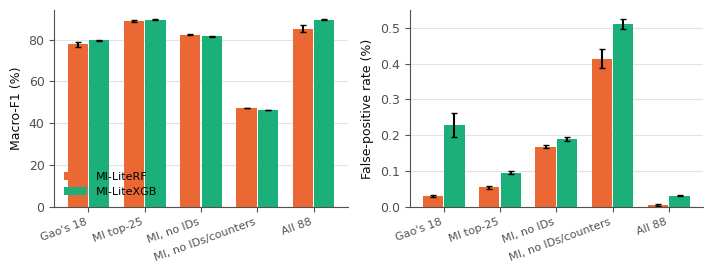

f1_macro                        exactitud                         \
             mean    std     min     max      mean    std     min     max   
variante                                                                    
tcn_cw      33.45  3.101  29.734  38.342    45.309  9.997  33.625  66.123   
tcn_mi25    64.56  4.180  54.466  68.004    88.178  3.428  80.101  90.241   

             tfp          ... ataque_normal_pct         epocas                 \
            mean     std  ...               min     max   mean    std min max   
variante                  ...                                                   
tcn_cw    59.552  14.279  ...              0.00  20.693   15.7  5.755  11  26   
tcn_mi25   2.556   4.500  ...             26.23  32.485   50.0  0.000  50  50   

             min                         
            mean    std     min     max  
variante                                 
tcn_cw     7.467  2.545   5.368  11.965  
tcn_mi25  22.752  0.134  22.547  22.978  

[2 rows x 24 columns]

{
 "generado": "22/11/2026 04:35",
 "E1": {
  "C1": {
   "comparación": "F1 macro (C): MI-LiteXGB v3 − TCN",
   "media_d": 53.71902593886064,
   "ic95_corr": "(49.7237, 57.7143)",
   "p_corr": 2.1966360260678379e-10,
   "p_corr_holm": 2.6359632312814055e-09,
   "p_clásica_holm": 1.5167173624829924e-12
  },
  "C2": {
   "comparación": "F1 macro (C): MI-LiteRF v3 − TCN",
   "media_d": 53.187470217108306,
   "ic95_corr": "(49.1535, 57.2215)",
   "p_corr": 2.6159970565919474e-10,
   "p_corr_holm": 2.877596762251142e-09,
   "p_clásica_holm": 1.657863274146042e-12
  },
  "C3": {
   "comparación": "F1 macro (C): MI-LiteXGB v3 − MI-LiteRF v3",
   "media_d": 0.5315557217523377,
   "ic95_corr": "(-0.667, 1.7302)",
   "p_corr": 0.34196043815302635,
   "p_corr_holm": 0.8172195912522859,
   "p_clásica_holm": 0.017578125
  },
  "C4": {
   "comparación": "F1 macro (C): RF sin balanceo − RF balanceado (v1)",
   "media_d": 13.47002128597608,
   "ic95_corr": "(11.7784, 15.1617)",
   "p_corr": 2.28070477

In [20]:
resumen = {'generado': datetime.datetime.now().strftime('%d/%m/%Y %H:%M')}
for nombre, archivo in [('E1', 'E1_pruebas_corregidas.json'), ('E2', 'E2_auditoria.json'), ('E3', 'E3_conflictos.json')]:
    ruta = os.path.join(DIR_E, archivo)
    if os.path.exists(ruta):
        d = leer_json(ruta)
        if nombre == 'E1':
            resumen['E1'] = {x['cod']: {k: x[k] for k in ('comparación', 'media_d', 'ic95_corr', 'p_corr', 'p_corr_holm', 'p_clásica_holm')} for x in d['pruebas']}
            resumen['E1_latencia'] = d['latencia']; resumen['E1_tfp_mayor_1pct'] = d['tfp_mayor_1pct']; resumen['E1_levene_tfp_p'] = d['levene_tfp_p']
        elif nombre == 'E2':
            resumen['E2'] = {k: d[k] for k in ('H_bin_bits', 'H_15_bits', 'base_pureza', 'n_normal', 'n_ataque', 'max_IM_bin_O', 'max_IM_bin_C',
                                               'separadores_O', 'separadores_C', 'max_pureza_C', 'atributo_max_pureza_C')}
            resumen['E2']['categoricas'] = [{'atributo': o['atributo'], 'IM_bin_O': o['IM_bin_bits'], 'pureza_O': o['pureza_bin'],
                                             'IM_bin_C': c['IM_bin_bits'], 'pureza_C': c['pureza_bin']} for o, c in zip(d['categoricas_O'], d['categoricas_C'])]
        else:
            resumen['E3'] = {n: {k: v for k, v in c.items() if k != 'por_clase'} | {'por_clase': {x['clase']: {kk: x[kk] for kk in ('ambiguo_pct', 'oraculo_normal_pct', 'f1_oraculo')} for x in c['por_clase']}}
                             for n, c in d['conjuntos'].items()}
filas = []
for r in TODAS_REPS:
    ruta = os.path.join(DIR_E, 'E4_ablaciones', f'REP-{r:02d}.json')
    if os.path.exists(ruta):
        for c, d in leer_json(ruta)['conjuntos'].items():
            for m_ in ('rf', 'xgb'):
                x = d[m_]
                filas.append({'rep': r, 'conjunto': c, 'modelo': m_, 'k': d['k'], 'f1_macro': x['f1_macro'], 'exactitud': x['exactitud'],
                              'f1_ponderado': x['f1_ponderado'], 'tfp': x['tfp'], 'ataque_normal_pct': x['ataque_normal_pct'], 'tamano_kb': x['tamano_kb'],
                              'lote1_us': x.get('lote1_us', np.nan), 'onnx_gzip_kb': x.get('onnx_gzip_kb', np.nan),
                              **{f'pc_{k}': v for k, v in x['f1_por_clase'].items()}})
if filas:
    E4T = pd.DataFrame(filas)
    # referencia mi25 = modelos v3 de S3, mismas REP
    for r in sorted(E4T.rep.unique()):
        f3 = ficha_de(DIR_S3, int(r))
        for m_, n_ in (('rf', 'rf_u3'), ('xgb', 'xgb_u3')):
            x = f3['modelos'][n_]
            E4T.loc[len(E4T)] = {'rep': r, 'conjunto': 'mi25', 'modelo': m_, 'k': 25, 'f1_macro': x['f1_macro'], 'exactitud': x['exactitud'],
                                 'f1_ponderado': x['f1_ponderado'], 'tfp': x['tfp'], 'ataque_normal_pct': ataque_normal_pct(f3['matrices_confusion'][n_]),
                                 'tamano_kb': x['tamano_kb'], 'lote1_us': x.get('lote1_ms', np.nan) * 1000, 'onnx_gzip_kb': x.get('tamano_onnx_gzip_kb', np.nan),
                                 **{f'pc_{k}': v for k, v in x['f1_por_clase'].items()}}
    vista = E4T.groupby(['conjunto', 'modelo'])[['k', 'f1_macro', 'exactitud', 'tfp', 'ataque_normal_pct', 'tamano_kb', 'lote1_us', 'onnx_gzip_kb']].agg(['mean', 'std'])
    display(vista.round(3))
    pruebas = []
    for c in [c for c in E4T.conjunto.unique() if c != 'mi25']:
        for m_ in ('rf', 'xgb'):
            a = E4T[(E4T.conjunto == 'mi25') & (E4T.modelo == m_)].set_index('rep')['f1_macro']
            b = E4T[(E4T.conjunto == c) & (E4T.modelo == m_)].set_index('rep')['f1_macro']
            comunes = a.index.intersection(b.index)
            if len(comunes) >= 3:
                tc = t_corregida((b - a).loc[comunes], 1336769, 572902)
                pruebas.append({'conjunto': c, 'modelo': m_, 'n': len(comunes), 'media_d_vs_mi25': tc['media_d'], 'ic95_corr': tc['ic95_corr'], 'p_corr': tc['p_corr']})
    if pruebas:
        P4 = pd.DataFrame(pruebas); P4['p_corr_holm'] = holm(P4['p_corr']); display(P4.round(4))
        resumen['E4_pruebas'] = P4.astype({'ic95_corr': str}).to_dict('records')
    resumen['E4'] = {f'{c}|{m}': {k: [float(g[k].mean()), float(g[k].std(ddof=1)) if len(g) > 1 else 0.0] for k in
                                  ('k', 'f1_macro', 'exactitud', 'tfp', 'ataque_normal_pct', 'tamano_kb', 'lote1_us', 'onnx_gzip_kb')} | {'n_reps': int(len(g))}
                     for (c, m), g in E4T.groupby(['conjunto', 'modelo'])}
    resumen['E4_atributos_rep1'] = {c: d['atributos'] for c, d in leer_json(os.path.join(DIR_E, 'E4_ablaciones', f'REP-{int(E4T.rep.min()):02d}.json'))['conjuntos'].items()}
    E4T.to_csv(os.path.join(DIR_E, 'E4_ablaciones.csv'), index=False)
    # Figura (inglés): F1 macro y TFP por conjunto de atributos
    orden = [c for c in ['gao18', 'mi25', 'sin_id', 'sin_id_cont', 'todos'] if c in E4T.conjunto.unique()]
    etq = {'gao18': "Gao's 18", 'mi25': 'MI top-25', 'sin_id': 'MI, no IDs', 'sin_id_cont': 'MI, no IDs/counters', 'todos': 'All 88'}
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for ax, col, lab in [(axs[0], 'f1_macro', 'Macro-F1 (%)'), (axs[1], 'tfp', 'False-positive rate (%)')]:
        for i, m_ in enumerate(('rf', 'xgb')):
            g = E4T[E4T.modelo == m_].groupby('conjunto')[col]
            mu, sd = g.mean().reindex(orden), g.std().reindex(orden)
            ax.bar(np.arange(len(orden)) + (i - 0.5) * 0.38, mu, 0.36, yerr=sd, color=COLOR[m_], label={'rf': 'MI-LiteRF', 'xgb': 'MI-LiteXGB'}[m_], capsize=2)
        ax.set_xticks(range(len(orden))); ax.set_xticklabels([etq[c] for c in orden], rotation=20, ha='right', fontsize=8)
        ax.set_ylabel(lab); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    axs[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(DIR_E, 'fig_E4_ablation.pdf')); fig.savefig(os.path.join(DIR_E, 'fig_E4_ablation.png'), dpi=200); plt.show()
filas5 = []
for v in E5_VARIANTES:
    for r in TODAS_REPS:
        ruta = os.path.join(DIR_E, 'E5_tcn', v, f'REP-{r:02d}', 'resultado.json')
        if os.path.exists(ruta):
            d = leer_json(ruta)
            filas5.append({'rep': r, 'variante': v, 'f1_macro': d['f1_macro'], 'exactitud': d['exactitud'], 'tfp': d['tfp'],
                           'ataque_normal_pct': d['ataque_normal_pct'], 'epocas': d['entrenamiento']['epocas_corridas'],
                           'min': d['entrenamiento']['tiempo_entrenamiento_s'] / 60, **{f'pc_{k}': x for k, x in d['f1_por_clase'].items()}})
if filas5:
    E5T = pd.DataFrame(filas5)
    display(E5T.groupby('variante')[['f1_macro', 'exactitud', 'tfp', 'ataque_normal_pct', 'epocas', 'min']].agg(['mean', 'std', 'min', 'max']).round(3))
    resumen['E5'] = {v: {k: [float(g[k].mean()), float(g[k].std(ddof=1)) if len(g) > 1 else 0.0, float(g[k].min()), float(g[k].max())]
                         for k in ('f1_macro', 'exactitud', 'tfp', 'ataque_normal_pct', 'epocas', 'min')} | {'n_reps': int(len(g)),
                         'f1_por_clase': {c: float(g[f'pc_{c}'].mean()) for c in CLASES}} for v, g in E5T.groupby('variante')}
    E5T.to_csv(os.path.join(DIR_E, 'E5_tcn.csv'), index=False)
for archivo in ('resultado_colab.json', 'resultado_borde.json'):
    ruta = os.path.join(DIR_E, 'E6_borde', archivo)
    if os.path.exists(ruta):
        resumen.setdefault('E6', {})[archivo] = leer_json(ruta)
guardar_json(resumen, os.path.join(DIR_E, 'S11e_resultados.json'))
print(json.dumps(resumen, ensure_ascii=False, indent=1, default=str)[:20000])

In [22]:
# (Opcional) Exportar este cuaderno a HTML y descargarlo, cuando haya terminado TODO.
# ⚠️ Primero guarda el cuaderno (Ctrl + S o Archivo → Guardar) y espera unos segundos: el HTML se arma con el .ipynb guardado en Drive.
import subprocess
from google.colab import files
ruta_ipynb = '/content/drive/MyDrive/Colab Notebooks/S11e_Paper.ipynb'
ruta_html = '/content/S11e_Paper.html'
subprocess.run(['jupyter', 'nbconvert', '--to', 'html', ruta_ipynb, '--output', ruta_html], check=True)
files.download(ruta_html)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>